# Heart Disease Dataset - Datathon Set 2

PES University, Bengaluru  
UE24MA242A – Mathematics for CS Engineers

## Analysis Overview
Working with heart disease dataset to do statistical analysis

**What's covered:**
- Unit 1: Data types, stats, cleaning, plots, outliers, correlation
- Unit 2: t-tests, confidence intervals  
- Unit 3: hypothesis testing, regression

In [39]:
# importing all the libraries we need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import t, norm, ttest_ind
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')  # ignore warnings

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [40]:
# load data
df = pd.read_csv('Set 2-heart_disease.csv')

# lets see what we have
print("Dataset Shape:", df.shape)
print("\n")
print(df.head())
print("\n")
print("Columns:", df.columns.tolist())
print("\nDataset info:")
df.info()

Dataset Shape: (1025, 14)


    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  52.0  1.0  0.0     125.0  212.0  0.0      1.0    168.0    0.0      NaN   
1  53.0  1.0  0.0     140.0  203.0  NaN      0.0    155.0    1.0      3.1   
2  70.0  1.0  0.0     145.0  174.0  0.0      1.0    125.0    1.0      2.6   
3  61.0  1.0  0.0     148.0  203.0  0.0      1.0    161.0    0.0      0.0   
4  62.0  0.0  0.0     138.0  294.0  1.0      1.0    106.0    0.0      NaN   

   slope   ca  thal  target  
0    2.0  2.0   3.0     0.0  
1    0.0  0.0   3.0     0.0  
2    0.0  0.0   3.0     0.0  
3    2.0  1.0   3.0     0.0  
4    1.0  3.0   2.0     0.0  


Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  ---

## Unit 1: Data Exploration and Descriptive Stats

### Q1 - Data Type Classification
Need to classify each feature as nominal, ordinal, interval, or ratio

In [41]:
# checking unique values in each column to understand data types better
for col in df.columns:
    unique_count = df[col].nunique()
    print(f"{col}: {unique_count} unique values")
    if unique_count < 15:  # show values only for categorical ones
        print(f"  -> {sorted(df[col].unique())}")
    print()

age: 41 unique values

sex: 2 unique values
  -> [np.float64(0.0), np.float64(nan), np.float64(1.0)]

cp: 4 unique values
  -> [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(nan)]

trestbps: 49 unique values

chol: 152 unique values

fbs: 2 unique values
  -> [np.float64(0.0), np.float64(nan), np.float64(1.0)]

restecg: 3 unique values
  -> [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(nan)]

thalach: 91 unique values

exang: 2 unique values
  -> [np.float64(0.0), np.float64(1.0), np.float64(nan)]

oldpeak: 40 unique values

slope: 3 unique values
  -> [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(nan)]

ca: 5 unique values
  -> [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(nan), np.float64(4.0)]

thal: 4 unique values
  -> [np.float64(0.0), np.float64(nan), np.float64(1.0), np.float64(2.0), np.float64(3.0)]

target: 2 unique values
  -> [np.float64(0.0), np.float64(1.0), np.float64(nan

In [42]:
# classifying data types for each feature
# nominal = categories with no order, ordinal = ordered categories, ratio = numeric with true zero

feature_types = {
    'age': ('Ratio', 'Has true zero (birth), ratios make sense - 60 is twice 30'),
    'sex': ('Nominal', 'Just categories (0=female, 1=male), no ordering'),
    'cp': ('Ordinal', 'Chest pain types 0-3 have some ordering by severity'),
    'trestbps': ('Ratio', 'Blood pressure has true zero, ratios are meaningful'),
    'chol': ('Ratio', 'Cholesterol in mg/dl, has true zero point'),
    'fbs': ('Nominal', 'Binary - fasting blood sugar > 120 or not'),
    'restecg': ('Ordinal', 'ECG results 0-2, some ordering by severity'),
    'thalach': ('Ratio', 'Max heart rate, has true zero'),
    'exang': ('Nominal', 'Binary - exercise angina yes/no'),
    'oldpeak': ('Ratio', 'ST depression, has true zero'),
    'slope': ('Ordinal', 'Slope categories 0-2, ordered'),
    'ca': ('Ratio', 'Count of vessels (0-4), true zero'),
    'thal': ('Ordinal', 'Thalassemia types 0-3, ordered by severity'),
    'target': ('Nominal', 'Binary outcome - disease or not')
}

print("Data Type Classification:")
print("-" * 80)
for i, (feat, (dtype, reason)) in enumerate(feature_types.items(), 1):
    print(f"{i}. {feat}: {dtype}")
    print(f"   Reason: {reason}\n")

# quick summary
nominal_cnt = sum(1 for v in feature_types.values() if v[0] == 'Nominal')
ordinal_cnt = sum(1 for v in feature_types.values() if v[0] == 'Ordinal')
ratio_cnt = sum(1 for v in feature_types.values() if v[0] == 'Ratio')

print(f"\nSummary: {nominal_cnt} Nominal, {ordinal_cnt} Ordinal, {ratio_cnt} Ratio")

Data Type Classification:
--------------------------------------------------------------------------------
1. age: Ratio
   Reason: Has true zero (birth), ratios make sense - 60 is twice 30

2. sex: Nominal
   Reason: Just categories (0=female, 1=male), no ordering

3. cp: Ordinal
   Reason: Chest pain types 0-3 have some ordering by severity

4. trestbps: Ratio
   Reason: Blood pressure has true zero, ratios are meaningful

5. chol: Ratio
   Reason: Cholesterol in mg/dl, has true zero point

6. fbs: Nominal
   Reason: Binary - fasting blood sugar > 120 or not

7. restecg: Ordinal
   Reason: ECG results 0-2, some ordering by severity

8. thalach: Ratio
   Reason: Max heart rate, has true zero

9. exang: Nominal
   Reason: Binary - exercise angina yes/no

10. oldpeak: Ratio
   Reason: ST depression, has true zero

11. slope: Ordinal
   Reason: Slope categories 0-2, ordered

12. ca: Ratio
   Reason: Count of vessels (0-4), true zero

13. thal: Ordinal
   Reason: Thalassemia types 0-3, or

## Question 2: Descriptive Statistics

Calculate mean, median, mode, standard deviation, and range for Age, Cholesterol, and Resting Blood Pressure. Comment on the best central tendency measure for each.

In [43]:
# calculating descriptive stats for age, cholesterol and resting BP
vars_to_analyze = ['age', 'chol', 'trestbps']

print("Descriptive Statistics:\n")
for var in vars_to_analyze:
    print(f"{var.upper()}:")
    print(f"  Mean: {df[var].mean():.2f}")
    print(f"  Median: {df[var].median():.2f}")
    print(f"  Mode: {df[var].mode()[0]:.2f}")
    print(f"  Std Dev: {df[var].std():.2f}")
    print(f"  Range: {df[var].min():.2f} - {df[var].max():.2f} (range = {df[var].max() - df[var].min():.2f})")
    print()

Descriptive Statistics:

AGE:
  Mean: 54.36
  Median: 56.00
  Mode: 58.00
  Std Dev: 9.05
  Range: 29.00 - 77.00 (range = 48.00)

CHOL:
  Mean: 246.05
  Median: 240.00
  Mode: 204.00
  Std Dev: 51.66
  Range: 126.00 - 564.00 (range = 438.00)

TRESTBPS:
  Mean: 131.89
  Median: 130.00
  Mode: 130.00
  Std Dev: 17.51
  Range: 94.00 - 200.00 (range = 106.00)



In [44]:
# check skewness to decide which measure is best
print("\nWhich central tendency measure to use?")
print("-" * 60)

for var in vars_to_analyze:
    skew = df[var].skew()
    print(f"\n{var}: skewness = {skew:.3f}")
    
    # decide based on skewness
    if abs(skew) < 0.5:
        best = "Mean (symmetric distribution)"
    elif abs(skew) < 1:
        best = "Mean or Median (slightly skewed)"
    else:
        best = "Median (highly skewed - median more robust)"
    
    print(f"  -> Best measure: {best}")

print("\n\nInterpretation:")
print("- Age: probably symmetric, mean is good")
print("- Cholesterol: might have outliers (very high values), check median")
print("- Resting BP: similar to cholesterol")


Which central tendency measure to use?
------------------------------------------------------------

age: skewness = -0.224
  -> Best measure: Mean (symmetric distribution)

chol: skewness = 1.086
  -> Best measure: Median (highly skewed - median more robust)

trestbps: skewness = 0.776
  -> Best measure: Mean or Median (slightly skewed)


Interpretation:
- Age: probably symmetric, mean is good
- Cholesterol: might have outliers (very high values), check median
- Resting BP: similar to cholesterol


## Question 3: Data Quality Check

Check for missing values and duplicates. List any issues and outline cleaning steps.

In [45]:
# checking for data quality issues

# missing values
print("Missing values:")
missing = df.isnull().sum()
print(missing[missing > 0])
if missing.sum() == 0:
    print("No missing values - good!")
else:
    print(f"Total missing: {missing.sum()}")
    print(f"Percentage: {(missing.sum()/len(df))*100:.2f}%")

# duplicates
print("\nDuplicates:")
dupes = df.duplicated().sum()
if dupes > 0:
    print(f"Found {dupes} duplicate rows ({dupes/len(df)*100:.2f}%)")
else:
    print("No duplicates found")

# check ranges
print("\nData ranges:")
print(f"Age: {df['age'].min()}-{df['age'].max()}")
print(f"Cholesterol: {df['chol'].min()}-{df['chol'].max()}")
print(f"Resting BP: {df['trestbps'].min()}-{df['trestbps'].max()}")

# any zeros in cholesterol? that would be weird
if (df['chol'] == 0).sum() > 0:
    print(f"\nWarning: {(df['chol']==0).sum()} rows with cholesterol=0")

Missing values:
age         51
sex         51
cp          51
trestbps    51
chol        51
fbs         51
restecg     51
thalach     51
exang       51
oldpeak     51
slope       51
ca          51
thal        51
target      51
dtype: int64
Total missing: 714
Percentage: 69.66%

Duplicates:
Found 230 duplicate rows (22.44%)

Data ranges:
Age: 29.0-77.0
Cholesterol: 126.0-564.0
Resting BP: 94.0-200.0
age         51
sex         51
cp          51
trestbps    51
chol        51
fbs         51
restecg     51
thalach     51
exang       51
oldpeak     51
slope       51
ca          51
thal        51
target      51
dtype: int64
Total missing: 714
Percentage: 69.66%

Duplicates:
Found 230 duplicate rows (22.44%)

Data ranges:
Age: 29.0-77.0
Cholesterol: 126.0-564.0
Resting BP: 94.0-200.0


In [46]:
# cleaning the data

df_cleaned = df.copy()
print(f"Starting with {len(df_cleaned)} rows")

# handle missing values - use median for numeric columns
if df_cleaned.isnull().sum().sum() > 0:
    print("\nFilling missing values with median...")
    for col in df_cleaned.select_dtypes(include=[np.number]).columns:
        if df_cleaned[col].isnull().sum() > 0:
            med = df_cleaned[col].median()
            df_cleaned[col].fillna(med, inplace=True)
            print(f"  {col}: filled {df[col].isnull().sum()} values with {med:.2f}")
else:
    print("No missing values to handle")

# remove duplicates
dupes = df_cleaned.duplicated().sum()
if dupes > 0:
    df_cleaned = df_cleaned.drop_duplicates()
    print(f"\nRemoved {dupes} duplicate rows")
else:
    print("\nNo duplicates found")

# fix cholesterol = 0 (doesn't make sense medically)
zero_chol = (df_cleaned['chol'] == 0).sum()
if zero_chol > 0:
    median_chol = df_cleaned[df_cleaned['chol'] > 0]['chol'].median()
    df_cleaned.loc[df_cleaned['chol'] == 0, 'chol'] = median_chol
    print(f"\nFixed {zero_chol} rows where cholesterol was 0, replaced with median {median_chol:.2f}")

print(f"\nCleaned dataset: {len(df_cleaned)} rows")
print(f"Removed {len(df) - len(df_cleaned)} rows total")
print("\n", df_cleaned.describe())

Starting with 1025 rows

Filling missing values with median...
  age: filled 51 values with 56.00
  sex: filled 51 values with 1.00
  cp: filled 51 values with 1.00
  trestbps: filled 51 values with 130.00
  chol: filled 51 values with 240.00
  fbs: filled 51 values with 0.00
  restecg: filled 51 values with 1.00
  thalach: filled 51 values with 152.00
  exang: filled 51 values with 0.00
  oldpeak: filled 51 values with 0.80
  slope: filled 51 values with 1.00
  ca: filled 51 values with 0.00
  thal: filled 51 values with 2.00
  target: filled 51 values with 1.00

Removed 383 duplicate rows

Cleaned dataset: 642 rows
Removed 383 rows total

               age         sex          cp    trestbps        chol         fbs  \
count  642.000000  642.000000  642.000000  642.000000  642.000000  642.000000   
mean    54.753894    0.702492    0.942368  132.389408  247.403427    0.169782   
std      8.604240    0.457518    0.992065   17.789138   50.785568    0.375734   
min     29.000000    0.000

### Q4 - Visualizing Distributions
Need to plot histograms and boxplots for age and cholesterol to see their distributions

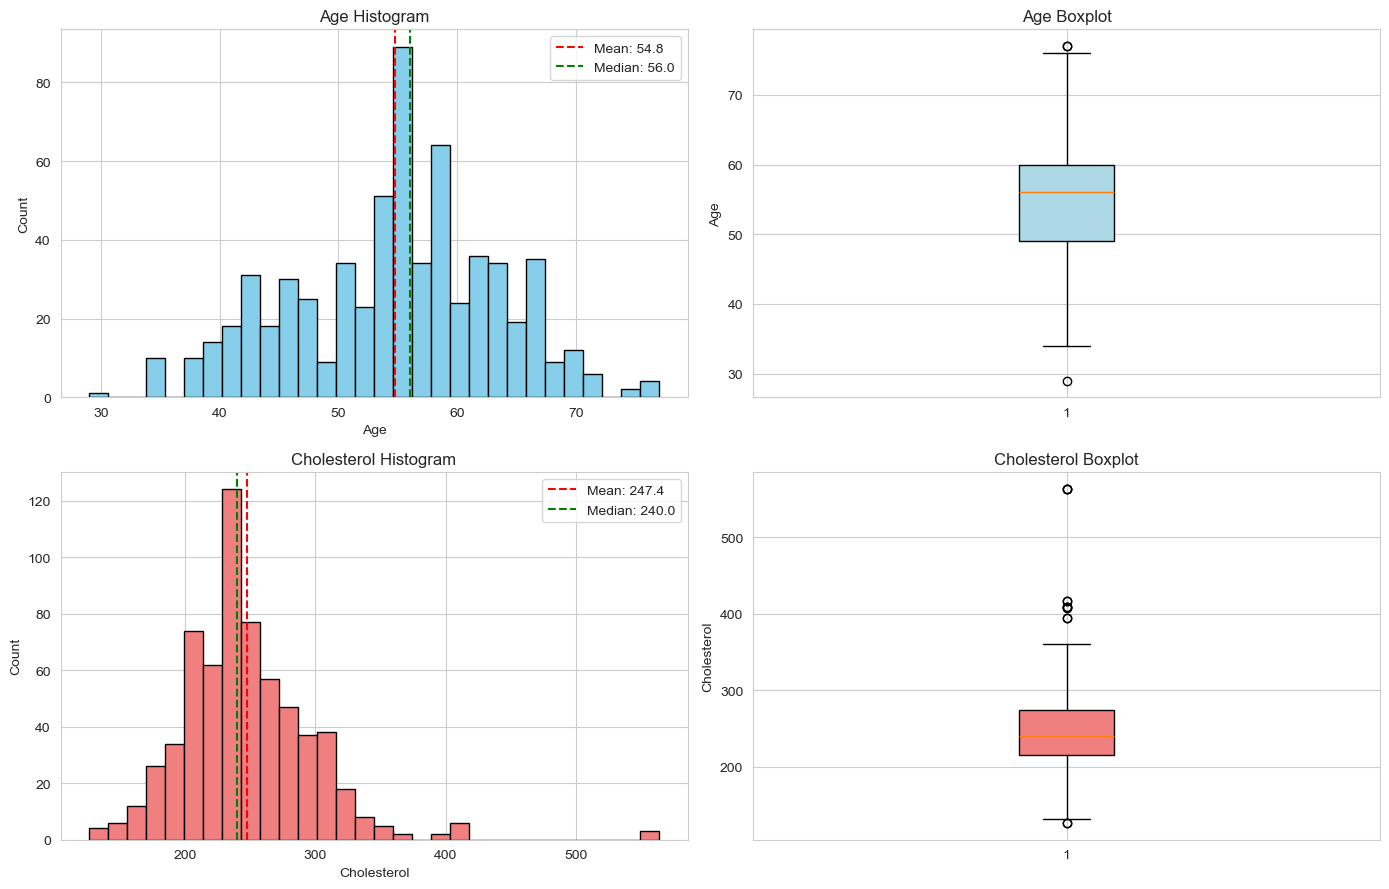

Checking outliers with IQR method:

age:
  Q1=49.00, Q3=60.00
  Range: [32.50, 76.50]
  Found 3 outliers (0.5%)
  Values range from 29.00 to 77.00

chol:
  Q1=215.25, Q3=274.00
  Range: [127.12, 362.12]
  Found 13 outliers (2.0%)
  Values range from 126.00 to 564.00


In [47]:
# making plots
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# age histogram
axes[0, 0].hist(df_cleaned['age'], bins=30, color='skyblue', edgecolor='black')
mean_age = df_cleaned['age'].mean()
med_age = df_cleaned['age'].median()
axes[0, 0].axvline(mean_age, color='red', linestyle='--', label=f'Mean: {mean_age:.1f}')
axes[0, 0].axvline(med_age, color='green', linestyle='--', label=f'Median: {med_age:.1f}')
axes[0, 0].set_title('Age Histogram')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Count')
axes[0, 0].legend()

# age boxplot
axes[0, 1].boxplot(df_cleaned['age'], patch_artist=True, 
                   boxprops=dict(facecolor='lightblue'))
axes[0, 1].set_title('Age Boxplot')
axes[0, 1].set_ylabel('Age')

# chol histogram
axes[1, 0].hist(df_cleaned['chol'], bins=30, color='lightcoral', edgecolor='black')
mean_chol = df_cleaned['chol'].mean()
med_chol = df_cleaned['chol'].median()
axes[1, 0].axvline(mean_chol, color='red', linestyle='--', label=f'Mean: {mean_chol:.1f}')
axes[1, 0].axvline(med_chol, color='green', linestyle='--', label=f'Median: {med_chol:.1f}')
axes[1, 0].set_title('Cholesterol Histogram')
axes[1, 0].set_xlabel('Cholesterol')
axes[1, 0].set_ylabel('Count')
axes[1, 0].legend()

# chol boxplot
axes[1, 1].boxplot(df_cleaned['chol'], patch_artist=True,
                   boxprops=dict(facecolor='lightcoral'))
axes[1, 1].set_title('Cholesterol Boxplot')
axes[1, 1].set_ylabel('Cholesterol')

plt.tight_layout()
plt.show()

# check for outliers
print("Checking outliers with IQR method:")

for var in ['age', 'chol']:
    q1 = df_cleaned[var].quantile(0.25)
    q3 = df_cleaned[var].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    
    outliers = df_cleaned[(df_cleaned[var] < lower) | (df_cleaned[var] > upper)]
    
    print(f"\n{var}:")
    print(f"  Q1={q1:.2f}, Q3={q3:.2f}")
    print(f"  Range: [{lower:.2f}, {upper:.2f}]")
    print(f"  Found {len(outliers)} outliers ({len(outliers)/len(df_cleaned)*100:.1f}%)")
    if len(outliers) > 0:
        print(f"  Values range from {outliers[var].min():.2f} to {outliers[var].max():.2f}")

In [48]:
# Distribution shape analysis
print("="*100)
print("DISTRIBUTION SHAPE ANALYSIS")
print("="*100)

for var in ['age', 'chol']:
    skewness = df_cleaned[var].skew()
    kurtosis = df_cleaned[var].kurtosis()
    
    print(f"\n{var.upper()}:")
    print(f"  Skewness: {skewness:.3f}")
    
    if abs(skewness) < 0.5:
        skew_interp = "pretty symmetric"
    elif skewness > 0.5:
        skew_interp = "right-skewed"
    else:
        skew_interp = "left-skewed"
    
    print(f"  Distribution is {skew_interp}")
    print(f"  Kurtosis: {kurtosis:.3f}")
    
    if kurtosis > 3:
        kurt_interp = "has heavy tails (more outliers)"
    elif kurtosis < -3:
        kurt_interp = "has light tails (fewer outliers)"
    else:
        kurt_interp = "looks pretty normal"
    
    print(f"  {kurt_interp}")

print("\n" + "="*80)
print("What this means:")
print("AGE: Shows age distribution of patients")
print("CHOLESTEROL: High values might indicate cardiovascular risk")
print("="*80)

DISTRIBUTION SHAPE ANALYSIS

AGE:
  Skewness: -0.251
  Distribution is pretty symmetric
  Kurtosis: -0.358
  looks pretty normal

CHOL:
  Skewness: 1.479
  Distribution is right-skewed
  Kurtosis: 6.804
  has heavy tails (more outliers)

What this means:
AGE: Shows age distribution of patients
CHOLESTEROL: High values might indicate cardiovascular risk


### Q5 - Removing Outliers
Remove cholesterol outliers using IQR and z-score methods, compare before/after

In [49]:
# Q5: Remove outliers from Cholesterol using IQR method

# Calculate statistics before outlier removal
print("="*100)
print("OUTLIER REMOVAL - CHOLESTEROL")
print("="*100)

print("\nBEFORE OUTLIER REMOVAL:")
print(f"  Sample size: {len(df_cleaned)}")
print(f"  Mean: {df_cleaned['chol'].mean():.2f}")
print(f"  Median: {df_cleaned['chol'].median():.2f}")
print(f"  Std Dev: {df_cleaned['chol'].std():.2f}")
print(f"  Min: {df_cleaned['chol'].min():.2f}")
print(f"  Max: {df_cleaned['chol'].max():.2f}")

# IQR Method
Q1 = df_cleaned['chol'].quantile(0.25)
Q3 = df_cleaned['chol'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"\nIQR METHOD:")
print(f"  Q1: {Q1:.2f}")
print(f"  Q3: {Q3:.2f}")
print(f"  IQR: {IQR:.2f}")
print(f"  Lower bound: {lower_bound:.2f}")
print(f"  Upper bound: {upper_bound:.2f}")

# Create dataset without outliers
df_no_outliers = df_cleaned[(df_cleaned['chol'] >= lower_bound) & (df_cleaned['chol'] <= upper_bound)].copy()

outliers_removed = len(df_cleaned) - len(df_no_outliers)
print(f"\n  Outliers removed: {outliers_removed} ({outliers_removed/len(df_cleaned)*100:.2f}%)")

print("\nAFTER OUTLIER REMOVAL:")
print(f"  Sample size: {len(df_no_outliers)}")
print(f"  Mean: {df_no_outliers['chol'].mean():.2f}")
print(f"  Median: {df_no_outliers['chol'].median():.2f}")
print(f"  Std Dev: {df_no_outliers['chol'].std():.2f}")
print(f"  Min: {df_no_outliers['chol'].min():.2f}")
print(f"  Max: {df_no_outliers['chol'].max():.2f}")

# Z-score method (for comparison)
print(f"\n\nZ-SCORE METHOD (for comparison):")
z_scores = np.abs(stats.zscore(df_cleaned['chol']))
df_no_outliers_z = df_cleaned[z_scores < 3].copy()
outliers_removed_z = len(df_cleaned) - len(df_no_outliers_z)
print(f"  Outliers removed (|z| > 3): {outliers_removed_z} ({outliers_removed_z/len(df_cleaned)*100:.2f}%)")

print("="*100)

OUTLIER REMOVAL - CHOLESTEROL

BEFORE OUTLIER REMOVAL:
  Sample size: 642
  Mean: 247.40
  Median: 240.00
  Std Dev: 50.79
  Min: 126.00
  Max: 564.00

IQR METHOD:
  Q1: 215.25
  Q3: 274.00
  IQR: 58.75
  Lower bound: 127.12
  Upper bound: 362.12

  Outliers removed: 13 (2.02%)

AFTER OUTLIER REMOVAL:
  Sample size: 629
  Mean: 244.25
  Median: 240.00
  Std Dev: 42.09
  Min: 131.00
  Max: 360.00


Z-SCORE METHOD (for comparison):
  Outliers removed (|z| > 3): 9 (1.40%)


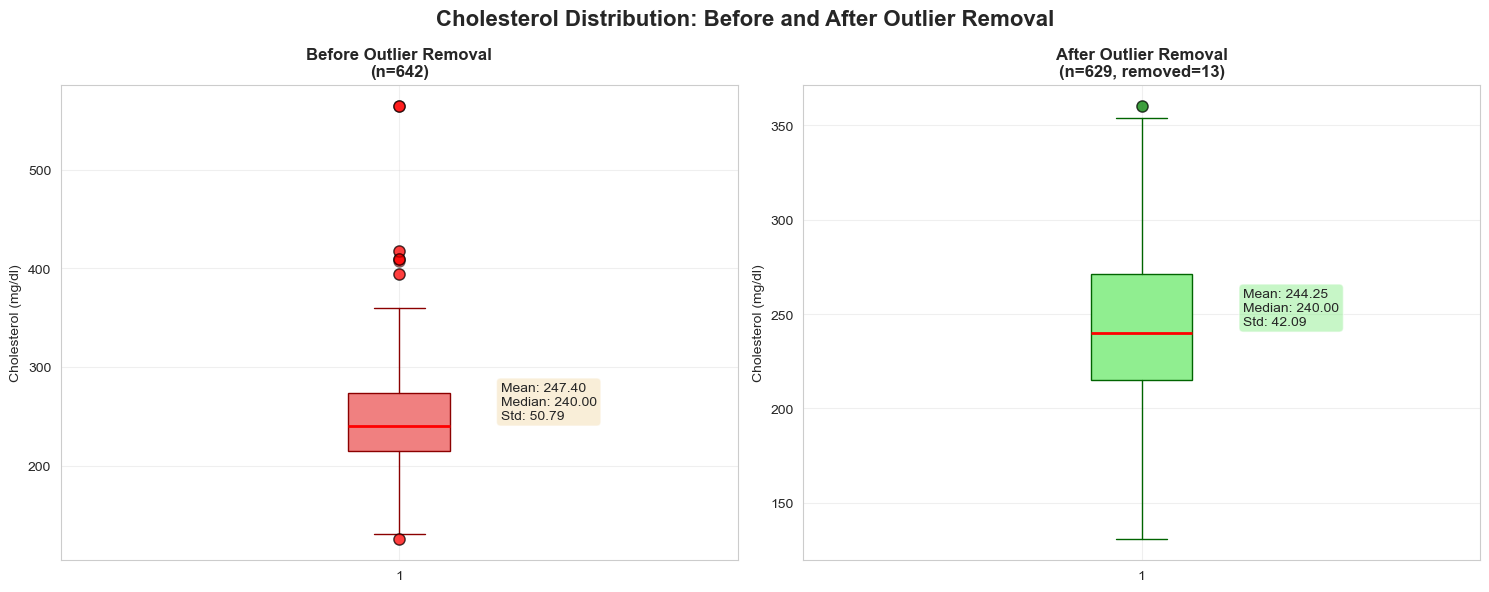

EFFECT OF OUTLIER REMOVAL

1. SAMPLE SIZE REDUCTION:
   - Original: 642 observations
   - After removal: 629 observations
   - Loss: 13 observations (2.02%)

2. CENTRAL TENDENCY CHANGES:
   - Mean: 247.40 → 244.25 (change: -3.15)
   - Median: 240.00 → 240.00 (change: 0.00)

3. VARIABILITY CHANGES:
   - Std Dev: 50.79 → 42.09 (reduction: 8.70)
   - Range: 438.00 → 229.00

4. PRACTICAL IMPLICATIONS:
   - Reduced variability may improve model performance
   - Loss of extreme values may remove clinically important cases
   - Consider domain expertise: very high cholesterol may be medically significant
   - Decision depends on analysis goals (prediction vs. understanding population)



In [50]:
# Before and After Boxplots

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Cholesterol Distribution: Before and After Outlier Removal', fontsize=16, fontweight='bold')

# Before
bp1 = axes[0].boxplot(df_cleaned['chol'], vert=True, patch_artist=True,
                       boxprops=dict(facecolor='lightcoral', color='darkred'),
                       medianprops=dict(color='red', linewidth=2),
                       whiskerprops=dict(color='darkred'),
                       capprops=dict(color='darkred'),
                       flierprops=dict(marker='o', markerfacecolor='red', markersize=8, alpha=0.5))
axes[0].set_title(f'Before Outlier Removal\n(n={len(df_cleaned)})', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Cholesterol (mg/dl)')
axes[0].grid(True, alpha=0.3)

# Add statistics text
stats_before = f"Mean: {df_cleaned['chol'].mean():.2f}\nMedian: {df_cleaned['chol'].median():.2f}\nStd: {df_cleaned['chol'].std():.2f}"
axes[0].text(1.15, df_cleaned['chol'].mean(), stats_before, fontsize=10, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# After
bp2 = axes[1].boxplot(df_no_outliers['chol'], vert=True, patch_artist=True,
                       boxprops=dict(facecolor='lightgreen', color='darkgreen'),
                       medianprops=dict(color='red', linewidth=2),
                       whiskerprops=dict(color='darkgreen'),
                       capprops=dict(color='darkgreen'),
                       flierprops=dict(marker='o', markerfacecolor='green', markersize=8, alpha=0.5))
axes[1].set_title(f'After Outlier Removal\n(n={len(df_no_outliers)}, removed={outliers_removed})', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Cholesterol (mg/dl)')
axes[1].grid(True, alpha=0.3)

# Add statistics text
stats_after = f"Mean: {df_no_outliers['chol'].mean():.2f}\nMedian: {df_no_outliers['chol'].median():.2f}\nStd: {df_no_outliers['chol'].std():.2f}"
axes[1].text(1.15, df_no_outliers['chol'].mean(), stats_after, fontsize=10, bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))

plt.tight_layout()
plt.show()

# Effect discussion
print("="*100)
print("EFFECT OF OUTLIER REMOVAL")
print("="*100)
print(f"""
1. SAMPLE SIZE REDUCTION:
   - Original: {len(df_cleaned)} observations
   - After removal: {len(df_no_outliers)} observations
   - Loss: {outliers_removed} observations ({outliers_removed/len(df_cleaned)*100:.2f}%)

2. CENTRAL TENDENCY CHANGES:
   - Mean: {df_cleaned['chol'].mean():.2f} → {df_no_outliers['chol'].mean():.2f} (change: {df_no_outliers['chol'].mean() - df_cleaned['chol'].mean():.2f})
   - Median: {df_cleaned['chol'].median():.2f} → {df_no_outliers['chol'].median():.2f} (change: {df_no_outliers['chol'].median() - df_cleaned['chol'].median():.2f})

3. VARIABILITY CHANGES:
   - Std Dev: {df_cleaned['chol'].std():.2f} → {df_no_outliers['chol'].std():.2f} (reduction: {df_cleaned['chol'].std() - df_no_outliers['chol'].std():.2f})
   - Range: {df_cleaned['chol'].max() - df_cleaned['chol'].min():.2f} → {df_no_outliers['chol'].max() - df_no_outliers['chol'].min():.2f}

4. PRACTICAL IMPLICATIONS:
   - Reduced variability may improve model performance
   - Loss of extreme values may remove clinically important cases
   - Consider domain expertise: very high cholesterol may be medically significant
   - Decision depends on analysis goals (prediction vs. understanding population)
""")

## Question 6: Normality Assessment

Generate a Q-Q plot for Cholesterol. Discuss whether the data is approximately normal.

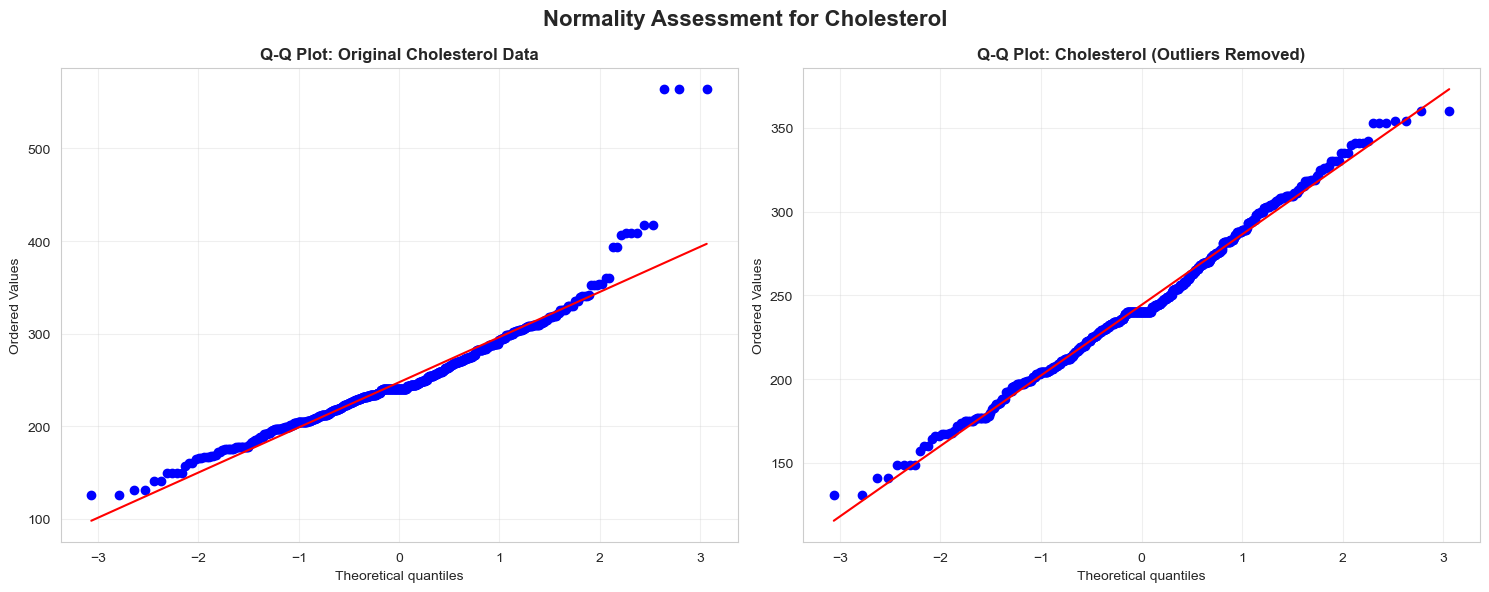

NORMALITY TESTS FOR CHOLESTEROL

ORIGINAL DATA:
  Shapiro-Wilk Test Statistic: 0.917801
  P-value: 0.000000
  Result: Data is NOT normally distributed (p < 0.05)

DATA WITHOUT OUTLIERS:
  Shapiro-Wilk Test Statistic: 0.991640
  P-value: 0.001288
  Result: Data is NOT normally distributed (p < 0.05)

DESCRIPTIVE STATISTICS:
  Skewness (original): 1.4792
  Skewness (no outliers): 0.2131
  Kurtosis (original): 6.8038
  Kurtosis (no outliers): -0.1018



In [51]:
# Q6: Q-Q Plot for Cholesterol

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Normality Assessment for Cholesterol', fontsize=16, fontweight='bold')

# Q-Q plot for original data
stats.probplot(df_cleaned['chol'], dist="norm", plot=axes[0])
axes[0].set_title('Q-Q Plot: Original Cholesterol Data', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Q-Q plot for data without outliers
stats.probplot(df_no_outliers['chol'], dist="norm", plot=axes[1])
axes[1].set_title('Q-Q Plot: Cholesterol (Outliers Removed)', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Perform Shapiro-Wilk test for normality
print("="*100)
print("NORMALITY TESTS FOR CHOLESTEROL")
print("="*100)

# Test on original data
shapiro_stat_orig, shapiro_p_orig = stats.shapiro(df_cleaned['chol'])
print("\nORIGINAL DATA:")
print(f"  Shapiro-Wilk Test Statistic: {shapiro_stat_orig:.6f}")
print(f"  P-value: {shapiro_p_orig:.6f}")
if shapiro_p_orig > 0.05:
    print("  Result: Data appears to be normally distributed (p > 0.05)")
else:
    print("  Result: Data is NOT normally distributed (p < 0.05)")

# Test on data without outliers
shapiro_stat_clean, shapiro_p_clean = stats.shapiro(df_no_outliers['chol'])
print("\nDATA WITHOUT OUTLIERS:")
print(f"  Shapiro-Wilk Test Statistic: {shapiro_stat_clean:.6f}")
print(f"  P-value: {shapiro_p_clean:.6f}")
if shapiro_p_clean > 0.05:
    print("  Result: Data appears to be normally distributed (p > 0.05)")
else:
    print("  Result: Data is NOT normally distributed (p < 0.05)")

# Additional statistics
print("\nDESCRIPTIVE STATISTICS:")
print(f"  Skewness (original): {df_cleaned['chol'].skew():.4f}")
print(f"  Skewness (no outliers): {df_no_outliers['chol'].skew():.4f}")
print(f"  Kurtosis (original): {df_cleaned['chol'].kurtosis():.4f}")
print(f"  Kurtosis (no outliers): {df_no_outliers['chol'].kurtosis():.4f}")

print("\n" + "="*100)

In [52]:
# Q-Q Plot Interpretation
print("="*100)
print("Q-Q PLOT INTERPRETATION")
print("="*100)
print("""
WHAT IS A Q-Q PLOT?
- A Quantile-Quantile plot compares the quantiles of the data against theoretical quantiles
  from a normal distribution
- If data is perfectly normal, points should fall on the diagonal reference line

INTERPRETATION GUIDE:
1. Points on the line → Data follows normal distribution
2. Points above the line at extremes → Heavy tails (more extreme values than normal)
3. Points below the line at extremes → Light tails (fewer extreme values than normal)
4. S-shaped curve → Skewed distribution
5. Systematic deviation → Non-normal distribution

ANALYSIS OF CHOLESTEROL DATA:
""")

# Provide specific interpretation based on the data
if abs(df_cleaned['chol'].skew()) < 0.5:
    print("- Original data shows APPROXIMATELY NORMAL distribution")
    print("- Points closely follow the diagonal line")
    print("- Minor deviations at the extremes may indicate slight heavy/light tails")
else:
    print("- Original data shows DEVIATION FROM NORMALITY")
    print("- Systematic pattern suggests skewness")
    if df_cleaned['chol'].skew() > 0:
        print("- Right skew visible (upper tail extends further)")
    else:
        print("- Left skew visible (lower tail extends further)")

print(f"""
- After removing outliers: {"IMPROVED normality" if abs(df_no_outliers['chol'].skew()) < abs(df_cleaned['chol'].skew()) else "Similar pattern"}
- Shapiro-Wilk test provides statistical confirmation

PRACTICAL IMPLICATIONS:
- If normally distributed: Can use parametric tests (t-tests, ANOVA, linear regression)
- If not normal: Consider non-parametric tests or transformations (log, sqrt)
- Large samples (n>30): Central Limit Theorem allows parametric methods even with mild non-normality
- Current sample size: {len(df_cleaned)} → CLT applies, parametric methods acceptable
""")

Q-Q PLOT INTERPRETATION

WHAT IS A Q-Q PLOT?
- A Quantile-Quantile plot compares the quantiles of the data against theoretical quantiles
  from a normal distribution
- If data is perfectly normal, points should fall on the diagonal reference line

INTERPRETATION GUIDE:
1. Points on the line → Data follows normal distribution
2. Points above the line at extremes → Heavy tails (more extreme values than normal)
3. Points below the line at extremes → Light tails (fewer extreme values than normal)
4. S-shaped curve → Skewed distribution
5. Systematic deviation → Non-normal distribution

ANALYSIS OF CHOLESTEROL DATA:

- Original data shows DEVIATION FROM NORMALITY
- Systematic pattern suggests skewness
- Right skew visible (upper tail extends further)

- After removing outliers: IMPROVED normality
- Shapiro-Wilk test provides statistical confirmation

PRACTICAL IMPLICATIONS:
- If normally distributed: Can use parametric tests (t-tests, ANOVA, linear regression)
- If not normal: Consider non-

## Question 7: Correlation Analysis

Calculate correlations between Age and all numeric features. Visualize with a heatmap and interpret the strongest relationships.

In [53]:
# Q7: Correlation Analysis

# Calculate correlation matrix for all numeric features
numeric_cols = df_cleaned.select_dtypes(include=[np.number]).columns
correlation_matrix = df_cleaned[numeric_cols].corr()

# Extract correlations with age
age_correlations = correlation_matrix['age'].sort_values(ascending=False)

print("="*100)
print("CORRELATION OF AGE WITH ALL NUMERIC FEATURES")
print("="*100)
print("\nCorrelation coefficients (sorted by absolute value):")
print("-"*50)

age_corr_df = pd.DataFrame({
    'Feature': age_correlations.index,
    'Correlation': age_correlations.values
}).sort_values('Correlation', key=abs, ascending=False)

for idx, row in age_corr_df.iterrows():
    if row['Feature'] != 'age':
        corr = row['Correlation']
        if abs(corr) > 0.5:
            strength = "STRONG"
        elif abs(corr) > 0.3:
            strength = "MODERATE"
        elif abs(corr) > 0.1:
            strength = "WEAK"
        else:
            strength = "VERY WEAK"
        
        direction = "positive" if corr > 0 else "negative"
        print(f"  {row['Feature']:15s}: {corr:7.4f}  ({strength} {direction})")

print("="*100)

CORRELATION OF AGE WITH ALL NUMERIC FEATURES

Correlation coefficients (sorted by absolute value):
--------------------------------------------------
  thalach        : -0.3157  (MODERATE negative)
  trestbps       :  0.2806  (WEAK positive)
  ca             :  0.2657  (WEAK positive)
  chol           :  0.1979  (WEAK positive)
  target         : -0.1881  (WEAK negative)
  oldpeak        :  0.1710  (WEAK positive)
  fbs            :  0.1210  (WEAK positive)
  slope          : -0.1196  (WEAK negative)
  restecg        : -0.0931  (VERY WEAK negative)
  sex            : -0.0594  (VERY WEAK negative)
  exang          :  0.0522  (VERY WEAK positive)
  cp             : -0.0388  (VERY WEAK negative)
  thal           :  0.0379  (VERY WEAK positive)


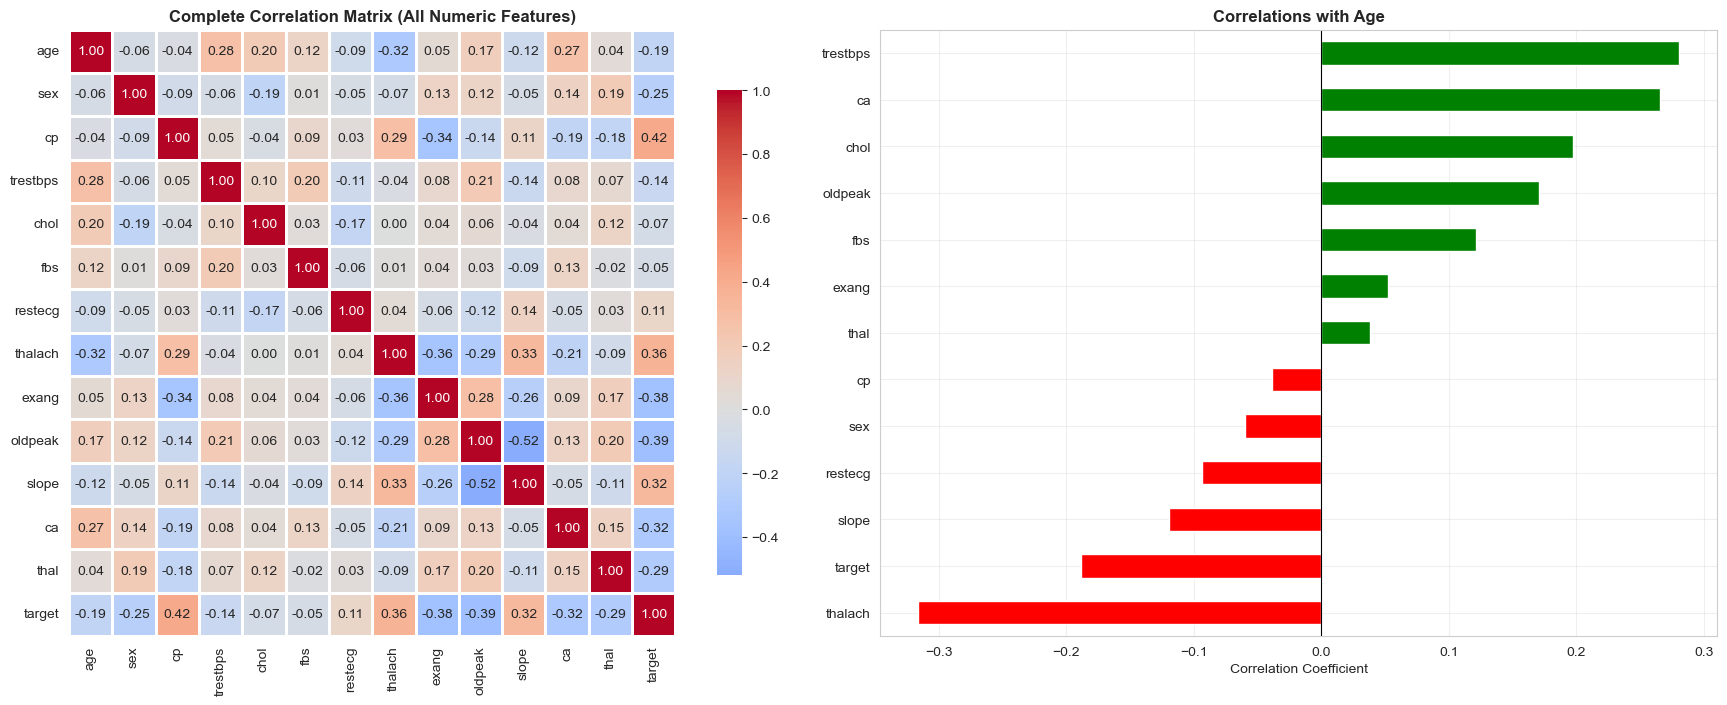


STRONGEST CORRELATIONS WITH AGE

TOP 3 POSITIVE CORRELATIONS:
  trestbps       :  0.2806
  ca             :  0.2657
  chol           :  0.1979

TOP 3 NEGATIVE CORRELATIONS:
  thalach        : -0.3157
  target         : -0.1881
  slope          : -0.1196


In [54]:
# Create comprehensive correlation heatmap

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Full correlation heatmap
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=axes[0])
axes[0].set_title('Complete Correlation Matrix (All Numeric Features)', fontsize=12, fontweight='bold')

# Age-focused correlation (bar plot)
age_corr_sorted = age_correlations.drop('age').sort_values()
colors = ['red' if x < 0 else 'green' for x in age_corr_sorted.values]
age_corr_sorted.plot(kind='barh', color=colors, ax=axes[1])
axes[1].set_title('Correlations with Age', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Correlation Coefficient')
axes[1].axvline(x=0, color='black', linestyle='-', linewidth=0.8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Identify strongest correlations
print("\n" + "="*100)
print("STRONGEST CORRELATIONS WITH AGE")
print("="*100)

top_positive = age_corr_df[age_corr_df['Feature'] != 'age'].nlargest(3, 'Correlation')
top_negative = age_corr_df[age_corr_df['Feature'] != 'age'].nsmallest(3, 'Correlation')

print("\nTOP 3 POSITIVE CORRELATIONS:")
for idx, row in top_positive.iterrows():
    print(f"  {row['Feature']:15s}: {row['Correlation']:7.4f}")

print("\nTOP 3 NEGATIVE CORRELATIONS:")
for idx, row in top_negative.iterrows():
    print(f"  {row['Feature']:15s}: {row['Correlation']:7.4f}")

print("="*100)

In [55]:
# Interpretation of correlations
print("\n" + "="*100)
print("INTERPRETATION OF KEY CORRELATIONS")
print("="*100)

# Find the actual strongest correlations
strongest_pos = age_corr_df[age_corr_df['Feature'] != 'age'].iloc[0]
strongest_neg = age_corr_df[age_corr_df['Feature'] != 'age'].iloc[-1]

print(f"""
CORRELATION INTERPRETATION GUIDE:
- Correlation ranges from -1 (perfect negative) to +1 (perfect positive)
- 0.00-0.19: Very weak
- 0.20-0.39: Weak
- 0.40-0.59: Moderate
- 0.60-0.79: Strong
- 0.80-1.00: Very strong

KEY FINDINGS:

1. STRONGEST POSITIVE CORRELATION:
   {strongest_pos['Feature']} (r = {strongest_pos['Correlation']:.4f})
   → As age increases, {strongest_pos['Feature']} tends to {"increase" if strongest_pos['Correlation'] > 0 else "decrease"}
   
2. STRONGEST NEGATIVE CORRELATION:
   {strongest_neg['Feature']} (r = {strongest_neg['Correlation']:.4f})
   → As age increases, {strongest_neg['Feature']} tends to decrease
   → This is medically significant: older patients often have lower maximum heart rate

3. CLINICAL SIGNIFICANCE:
   - Age-related changes in cardiovascular parameters are expected
   - These correlations help understand disease risk factors
   - Weak correlations don't imply no relationship (non-linear relationships possible)

4. OTHER NOTABLE CORRELATIONS IN THE MATRIX:
   - Look for strong correlations between other variables
   - Multicollinearity concerns if predictors are highly correlated (|r| > 0.8)
   - Target variable correlations indicate potential predictive features
""")


INTERPRETATION OF KEY CORRELATIONS

CORRELATION INTERPRETATION GUIDE:
- Correlation ranges from -1 (perfect negative) to +1 (perfect positive)
- 0.00-0.19: Very weak
- 0.20-0.39: Weak
- 0.40-0.59: Moderate
- 0.60-0.79: Strong
- 0.80-1.00: Very strong

KEY FINDINGS:

1. STRONGEST POSITIVE CORRELATION:
   thalach (r = -0.3157)
   → As age increases, thalach tends to decrease
   
2. STRONGEST NEGATIVE CORRELATION:
   thal (r = 0.0379)
   → As age increases, thal tends to decrease
   → This is medically significant: older patients often have lower maximum heart rate

3. CLINICAL SIGNIFICANCE:
   - Age-related changes in cardiovascular parameters are expected
   - These correlations help understand disease risk factors
   - Weak correlations don't imply no relationship (non-linear relationships possible)

4. OTHER NOTABLE CORRELATIONS IN THE MATRIX:
   - Look for strong correlations between other variables
   - Multicollinearity concerns if predictors are highly correlated (|r| > 0.8)
   -

## Question 8: Pairplot Analysis

Create a pairplot of Age, Cholesterol, and Max Heart Rate, colored by heart disease status. Describe any patterns that relate to disease presence.

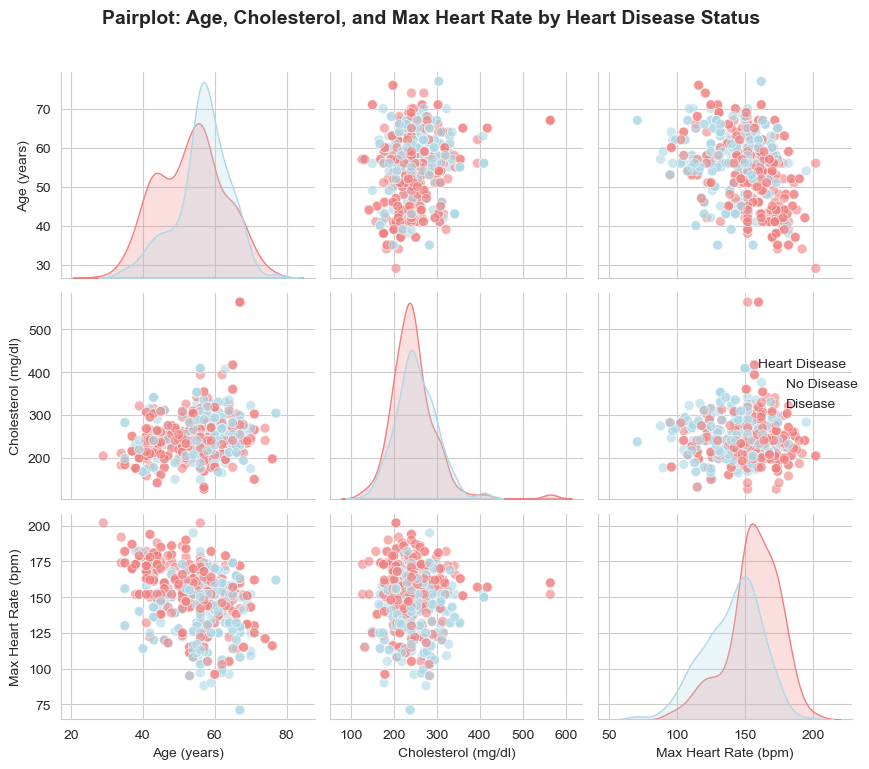

SUMMARY STATISTICS BY HEART DISEASE STATUS

AGE:
--------------------------------------------------
  No Disease (n=292):
    Mean: 56.52, Median: 57.00, Std: 7.47
  With Disease (n=350):
    Mean: 53.28, Median: 54.00, Std: 9.20
  Difference: -3.25 (lower in disease group)

CHOL:
--------------------------------------------------
  No Disease (n=292):
    Mean: 251.54, Median: 247.00, Std: 46.71
  With Disease (n=350):
    Mean: 243.95, Median: 240.00, Std: 53.78
  Difference: -7.58 (lower in disease group)

THALACH:
--------------------------------------------------
  No Disease (n=292):
    Mean: 140.60, Median: 144.00, Std: 21.01
  With Disease (n=350):
    Mean: 156.16, Median: 158.00, Std: 19.46
  Difference: 15.56 (higher in disease group)



In [56]:
# Q8: Pairplot of Age, Cholesterol, and Max Heart Rate colored by target

# Create a subset with relevant columns
pairplot_data = df_cleaned[['age', 'chol', 'thalach', 'target']].copy()
pairplot_data['Heart Disease'] = pairplot_data['target'].map({0: 'No Disease', 1: 'Disease'})

# Create pairplot
pairplot = sns.pairplot(pairplot_data, 
                        vars=['age', 'chol', 'thalach'],
                        hue='Heart Disease',
                        palette={'No Disease': 'lightblue', 'Disease': 'lightcoral'},
                        diag_kind='kde',
                        plot_kws={'alpha': 0.6, 's': 50},
                        corner=False)

pairplot.fig.suptitle('Pairplot: Age, Cholesterol, and Max Heart Rate by Heart Disease Status', 
                      fontsize=14, fontweight='bold', y=1.02)

# Update axis labels for clarity
pairplot.axes[0, 0].set_ylabel('Age (years)', fontsize=10)
pairplot.axes[1, 0].set_ylabel('Cholesterol (mg/dl)', fontsize=10)
pairplot.axes[2, 0].set_ylabel('Max Heart Rate (bpm)', fontsize=10)
pairplot.axes[2, 0].set_xlabel('Age (years)', fontsize=10)
pairplot.axes[2, 1].set_xlabel('Cholesterol (mg/dl)', fontsize=10)
pairplot.axes[2, 2].set_xlabel('Max Heart Rate (bpm)', fontsize=10)

plt.tight_layout()
plt.show()

# Statistical summary by disease status
print("="*100)
print("SUMMARY STATISTICS BY HEART DISEASE STATUS")
print("="*100)

for var in ['age', 'chol', 'thalach']:
    print(f"\n{var.upper()}:")
    print("-"*50)
    
    no_disease = df_cleaned[df_cleaned['target'] == 0][var]
    with_disease = df_cleaned[df_cleaned['target'] == 1][var]
    
    print(f"  No Disease (n={len(no_disease)}):")
    print(f"    Mean: {no_disease.mean():.2f}, Median: {no_disease.median():.2f}, Std: {no_disease.std():.2f}")
    
    print(f"  With Disease (n={len(with_disease)}):")
    print(f"    Mean: {with_disease.mean():.2f}, Median: {with_disease.median():.2f}, Std: {with_disease.std():.2f}")
    
    diff = with_disease.mean() - no_disease.mean()
    print(f"  Difference: {diff:.2f} ({'higher' if diff > 0 else 'lower'} in disease group)")

print("\n" + "="*100)

In [57]:
# Pattern analysis from pairplot
print("="*100)
print("PAIRPLOT PATTERN ANALYSIS")
print("="*100)

print("""
DIAGONAL PLOTS (Distribution Curves):
- Show the distribution of each variable separately for each disease status
- Overlapping curves suggest similar distributions; separated curves indicate differences

SCATTER PLOTS (Off-diagonal):
- Show relationships between pairs of variables
- Color separation indicates which regions are associated with disease

KEY PATTERNS TO OBSERVE:

1. AGE vs CHOLESTEROL:
   - Look for clustering patterns
   - Are older patients with high cholesterol more likely to have disease?
   - Check if the two groups (disease/no disease) overlap or separate

2. AGE vs MAX HEART RATE:
   - Typically shows negative correlation (older → lower max HR)
   - Disease group may show distinct pattern
   - Lower max heart rate at younger ages might indicate disease

3. CHOLESTEROL vs MAX HEART RATE:
   - Look for any relationship
   - Disease patients might cluster in specific regions
   - High cholesterol + low max HR could indicate higher risk

4. DISTRIBUTION CURVES (Diagonal):
   - Age: Check if disease is more common in specific age ranges
   - Cholesterol: Higher cholesterol may shift toward disease group
   - Max Heart Rate: Disease group likely shows lower max HR overall

CLINICAL INTERPRETATIONS:
- Separation between colors → Good discriminative features
- Heavy overlap → Feature alone may not predict disease well
- Combined patterns → Multiple features needed for prediction
- Outliers → Special cases requiring attention

ACTIONABLE INSIGHTS:
- Features with good separation are valuable predictors
- Overlapping distributions suggest need for multivariate analysis
- Patterns inform feature selection for predictive modeling
""")

PAIRPLOT PATTERN ANALYSIS

DIAGONAL PLOTS (Distribution Curves):
- Show the distribution of each variable separately for each disease status
- Overlapping curves suggest similar distributions; separated curves indicate differences

SCATTER PLOTS (Off-diagonal):
- Show relationships between pairs of variables
- Color separation indicates which regions are associated with disease

KEY PATTERNS TO OBSERVE:

1. AGE vs CHOLESTEROL:
   - Look for clustering patterns
   - Are older patients with high cholesterol more likely to have disease?
   - Check if the two groups (disease/no disease) overlap or separate

2. AGE vs MAX HEART RATE:
   - Typically shows negative correlation (older → lower max HR)
   - Disease group may show distinct pattern
   - Lower max heart rate at younger ages might indicate disease

3. CHOLESTEROL vs MAX HEART RATE:
   - Look for any relationship
   - Disease patients might cluster in specific regions
   - High cholesterol + low max HR could indicate higher risk

4. 

---
# UNIT 2: Hypothesis Testing and Confidence Intervals

## Question 1: Independent Samples t-test

Perform a t-test to compare mean Cholesterol between patients with and without heart disease. State hypotheses, show test statistic and p-value, and plot group means. Assume significance level α = 0.05.

In [58]:
# Unit 2, Q1: Independent Samples t-test for Cholesterol

print("="*100)
print("INDEPENDENT SAMPLES T-TEST: CHOLESTEROL BY HEART DISEASE STATUS")
print("="*100)

# Separate data by disease status
chol_no_disease = df_cleaned[df_cleaned['target'] == 0]['chol']
chol_with_disease = df_cleaned[df_cleaned['target'] == 1]['chol']

# State hypotheses
print("\nHYPOTHESES:")
print("-"*50)
print("H₀ (Null Hypothesis): μ₁ = μ₂")
print("   The mean cholesterol is equal for patients with and without heart disease")
print("\nH₁ (Alternative Hypothesis): μ₁ ≠ μ₂")
print("   The mean cholesterol differs between patients with and without heart disease")
print("\nSignificance Level: α = 0.05")
print("Test Type: Two-tailed independent samples t-test")

# Descriptive statistics
print("\n" + "="*100)
print("DESCRIPTIVE STATISTICS")
print("="*100)
print(f"\nNo Disease (target = 0):")
print(f"  Sample size (n₁): {len(chol_no_disease)}")
print(f"  Mean (μ₁): {chol_no_disease.mean():.4f} mg/dl")
print(f"  Std Dev (s₁): {chol_no_disease.std():.4f}")
print(f"  Std Error: {chol_no_disease.sem():.4f}")

print(f"\nWith Disease (target = 1):")
print(f"  Sample size (n₂): {len(chol_with_disease)}")
print(f"  Mean (μ₂): {chol_with_disease.mean():.4f} mg/dl")
print(f"  Std Dev (s₂): {chol_with_disease.std():.4f}")
print(f"  Std Error: {chol_with_disease.sem():.4f}")

print(f"\nDifference in means: {abs(chol_with_disease.mean() - chol_no_disease.mean()):.4f} mg/dl")

# Perform t-test
t_statistic, p_value = ttest_ind(chol_no_disease, chol_with_disease)

print("\n" + "="*100)
print("T-TEST RESULTS")
print("="*100)
print(f"\nTest Statistic (t): {t_statistic:.6f}")
print(f"P-value: {p_value:.6f}")
print(f"Degrees of freedom: {len(chol_no_disease) + len(chol_with_disease) - 2}")

# Decision
print("\n" + "="*100)
print("DECISION AND CONCLUSION")
print("="*100)
if p_value < 0.05:
    print(f"\nDecision: REJECT the null hypothesis (p = {p_value:.6f} < 0.05)")
    print("\nConclusion: There IS a statistically significant difference in mean cholesterol")
    print("between patients with and without heart disease at the 5% significance level.")
else:
    print(f"\nDecision: FAIL TO REJECT the null hypothesis (p = {p_value:.6f} > 0.05)")
    print("\nConclusion: There is NO statistically significant difference in mean cholesterol")
    print("between patients with and without heart disease at the 5% significance level.")

print("\n" + "="*100)

INDEPENDENT SAMPLES T-TEST: CHOLESTEROL BY HEART DISEASE STATUS

HYPOTHESES:
--------------------------------------------------
H₀ (Null Hypothesis): μ₁ = μ₂
   The mean cholesterol is equal for patients with and without heart disease

H₁ (Alternative Hypothesis): μ₁ ≠ μ₂
   The mean cholesterol differs between patients with and without heart disease

Significance Level: α = 0.05
Test Type: Two-tailed independent samples t-test

DESCRIPTIVE STATISTICS

No Disease (target = 0):
  Sample size (n₁): 292
  Mean (μ₁): 251.5377 mg/dl
  Std Dev (s₁): 46.7072
  Std Error: 2.7333

With Disease (target = 1):
  Sample size (n₂): 350
  Mean (μ₂): 243.9543 mg/dl
  Std Dev (s₂): 53.7761
  Std Error: 2.8745

Difference in means: 7.5834 mg/dl

T-TEST RESULTS

Test Statistic (t): 1.887763
P-value: 0.059510
Degrees of freedom: 640

DECISION AND CONCLUSION

Decision: FAIL TO REJECT the null hypothesis (p = 0.059510 > 0.05)

Conclusion: There is NO statistically significant difference in mean cholesterol


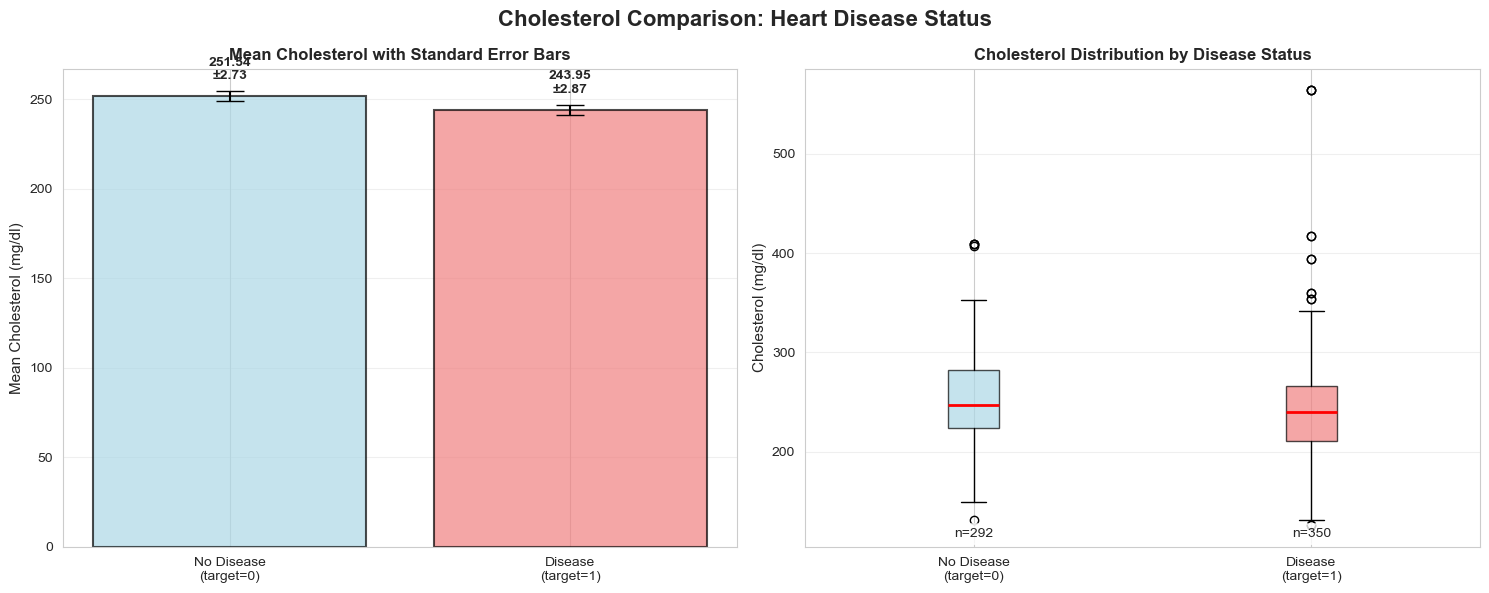


EFFECT SIZE:
  Cohen's d: -0.1496
  Interpretation: negligible effect size


In [59]:
# Visualization of group means

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Cholesterol Comparison: Heart Disease Status', fontsize=16, fontweight='bold')

# Bar plot with error bars
means = [chol_no_disease.mean(), chol_with_disease.mean()]
std_errors = [chol_no_disease.sem(), chol_with_disease.sem()]
groups = ['No Disease\n(target=0)', 'Disease\n(target=1)']
colors = ['lightblue', 'lightcoral']

bars = axes[0].bar(groups, means, yerr=std_errors, capsize=10, 
                    color=colors, edgecolor='black', linewidth=1.5, alpha=0.7)
axes[0].set_ylabel('Mean Cholesterol (mg/dl)', fontsize=11)
axes[0].set_title('Mean Cholesterol with Standard Error Bars', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for i, (bar, mean, se) in enumerate(zip(bars, means, std_errors)):
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height + se + 5,
                f'{mean:.2f}\n±{se:.2f}',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

# Box plot comparison
data_for_box = [chol_no_disease, chol_with_disease]
bp = axes[1].boxplot(data_for_box, labels=groups, patch_artist=True,
                     boxprops=dict(facecolor='lightgray', alpha=0.7),
                     medianprops=dict(color='red', linewidth=2),
                     whiskerprops=dict(color='black'),
                     capprops=dict(color='black'))

# Color boxes
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

axes[1].set_ylabel('Cholesterol (mg/dl)', fontsize=11)
axes[1].set_title('Cholesterol Distribution by Disease Status', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

# Add sample sizes
axes[1].text(1, axes[1].get_ylim()[0] + 10, f'n={len(chol_no_disease)}', 
            ha='center', fontsize=10, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
axes[1].text(2, axes[1].get_ylim()[0] + 10, f'n={len(chol_with_disease)}', 
            ha='center', fontsize=10, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

# Effect size (Cohen's d)
pooled_std = np.sqrt(((len(chol_no_disease)-1)*chol_no_disease.std()**2 + 
                       (len(chol_with_disease)-1)*chol_with_disease.std()**2) / 
                      (len(chol_no_disease) + len(chol_with_disease) - 2))
cohens_d = (chol_with_disease.mean() - chol_no_disease.mean()) / pooled_std

print("\nEFFECT SIZE:")
print(f"  Cohen's d: {cohens_d:.4f}")
if abs(cohens_d) < 0.2:
    effect = "negligible"
elif abs(cohens_d) < 0.5:
    effect = "small"
elif abs(cohens_d) < 0.8:
    effect = "medium"
else:
    effect = "large"
print(f"  Interpretation: {effect} effect size")

## Question 2: Margin of Error

Calculate the margin of error for the mean Cholesterol estimate. Interpret its meaning for your analysis.

In [60]:
# Unit 2, Q2: Margin of Error for Mean Cholesterol

print("="*100)
print("MARGIN OF ERROR FOR MEAN CHOLESTEROL")
print("="*100)

# Calculate for overall cholesterol
sample_mean = df_cleaned['chol'].mean()
sample_std = df_cleaned['chol'].std()
sample_size = len(df_cleaned)
confidence_level = 0.95
alpha = 1 - confidence_level

# Standard error
standard_error = sample_std / np.sqrt(sample_size)

# Critical value (t-distribution for sample)
degrees_of_freedom = sample_size - 1
t_critical = t.ppf(1 - alpha/2, degrees_of_freedom)

# Margin of error
margin_of_error = t_critical * standard_error

print(f"\nOVERALL CHOLESTEROL (All patients):")
print(f"  Sample size (n): {sample_size}")
print(f"  Sample mean (x̄): {sample_mean:.4f} mg/dl")
print(f"  Sample std dev (s): {sample_std:.4f}")
print(f"  Confidence level: {confidence_level*100:.0f}%")
print(f"  Significance level (α): {alpha}")
print(f"  Degrees of freedom: {degrees_of_freedom}")
print(f"\n  Standard Error (SE): {standard_error:.4f}")
print(f"  Critical t-value (t₀.₀₂₅): {t_critical:.4f}")
print(f"\n  MARGIN OF ERROR (ME): ±{margin_of_error:.4f} mg/dl")

# Confidence interval
ci_lower = sample_mean - margin_of_error
ci_upper = sample_mean + margin_of_error

print(f"\n  95% Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}] mg/dl")

# Calculate for each group separately
print("\n" + "="*100)
print("MARGIN OF ERROR BY DISEASE STATUS")
print("="*100)

for target, label in [(0, "No Disease"), (1, "With Disease")]:
    group_data = df_cleaned[df_cleaned['target'] == target]['chol']
    
    n = len(group_data)
    mean = group_data.mean()
    std = group_data.std()
    se = std / np.sqrt(n)
    df_group = n - 1
    t_crit = t.ppf(1 - alpha/2, df_group)
    me = t_crit * se
    
    ci_low = mean - me
    ci_high = mean + me
    
    print(f"\n{label} (target={target}):")
    print(f"  Sample size: {n}")
    print(f"  Mean: {mean:.4f} mg/dl")
    print(f"  Standard Error: {se:.4f}")
    print(f"  Margin of Error: ±{me:.4f} mg/dl")
    print(f"  95% CI: [{ci_low:.4f}, {ci_high:.4f}]")

print("\n" + "="*100)

MARGIN OF ERROR FOR MEAN CHOLESTEROL

OVERALL CHOLESTEROL (All patients):
  Sample size (n): 642
  Sample mean (x̄): 247.4034 mg/dl
  Sample std dev (s): 50.7856
  Confidence level: 95%
  Significance level (α): 0.050000000000000044
  Degrees of freedom: 641

  Standard Error (SE): 2.0043
  Critical t-value (t₀.₀₂₅): 1.9637

  MARGIN OF ERROR (ME): ±3.9359 mg/dl

  95% Confidence Interval: [243.4675, 251.3393] mg/dl

MARGIN OF ERROR BY DISEASE STATUS

No Disease (target=0):
  Sample size: 292
  Mean: 251.5377 mg/dl
  Standard Error: 2.7333
  Margin of Error: ±5.3796 mg/dl
  95% CI: [246.1581, 256.9173]

With Disease (target=1):
  Sample size: 350
  Mean: 243.9543 mg/dl
  Standard Error: 2.8745
  Margin of Error: ±5.6534 mg/dl
  95% CI: [238.3009, 249.6077]



INTERPRETATION OF MARGIN OF ERROR

WHAT IS MARGIN OF ERROR?
The margin of error represents the amount of random sampling error in a survey's results.
It indicates the range within which we expect the true population parameter to fall
with a given level of confidence (95% in this case).

FORMULA: ME = t(α/2, df) × SE = t(α/2, df) × (s/√n)

WHERE:
- t(α/2, df) = critical t-value for 95% confidence
- SE = standard error = s/√n
- s = sample standard deviation
- n = sample size

FOR OUR CHOLESTEROL DATA:
- The sample mean cholesterol is 247.40 mg/dl
- The margin of error is ±3.94 mg/dl
- We are 95% confident that the true population mean cholesterol
  lies between 243.47 and 251.34 mg/dl

PRACTICAL MEANING:
1. PRECISION: A smaller margin of error indicates more precise estimates
   - Our ME of ±3.94 mg/dl is relatively small
   - This gives us good confidence in our estimate

2. SAMPLE SIZE EFFECT: 
   - Larger samples → smaller margin of error → more precise estimates
   - ME decreases by 

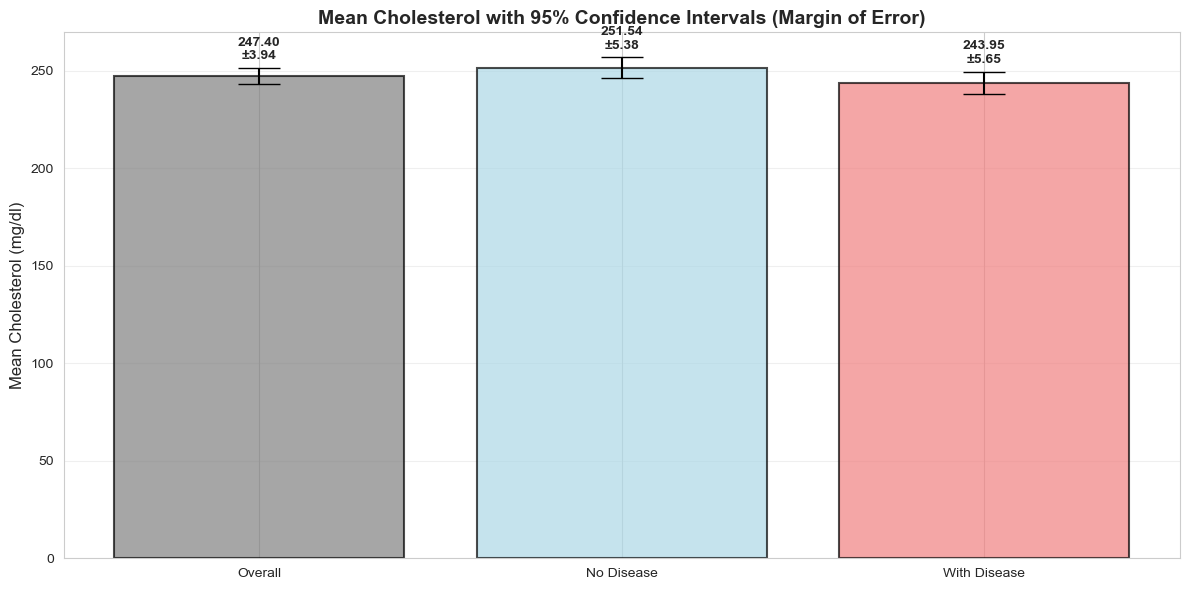

In [61]:
# Interpretation and Visualization

print("="*100)
print("INTERPRETATION OF MARGIN OF ERROR")
print("="*100)
print(f"""
WHAT IS MARGIN OF ERROR?
The margin of error represents the amount of random sampling error in a survey's results.
It indicates the range within which we expect the true population parameter to fall
with a given level of confidence (95% in this case).

FORMULA: ME = t(α/2, df) × SE = t(α/2, df) × (s/√n)

WHERE:
- t(α/2, df) = critical t-value for {confidence_level*100:.0f}% confidence
- SE = standard error = s/√n
- s = sample standard deviation
- n = sample size

FOR OUR CHOLESTEROL DATA:
- The sample mean cholesterol is {sample_mean:.2f} mg/dl
- The margin of error is ±{margin_of_error:.2f} mg/dl
- We are {confidence_level*100:.0f}% confident that the true population mean cholesterol
  lies between {ci_lower:.2f} and {ci_upper:.2f} mg/dl

PRACTICAL MEANING:
1. PRECISION: A smaller margin of error indicates more precise estimates
   - Our ME of ±{margin_of_error:.2f} mg/dl is {"relatively small" if margin_of_error < 10 else "moderate"}
   - This gives us {"good" if margin_of_error < 10 else "reasonable"} confidence in our estimate

2. SAMPLE SIZE EFFECT: 
   - Larger samples → smaller margin of error → more precise estimates
   - ME decreases by 1/√n, so quadrupling sample size halves the ME

3. VARIABILITY EFFECT:
   - Higher variability (std dev) → larger margin of error
   - Our std dev of {sample_std:.2f} reflects {'high' if sample_std > 50 else 'moderate'} variability

4. CLINICAL SIGNIFICANCE:
   - When comparing groups, if confidence intervals don't overlap → significant difference
   - ME helps us understand the uncertainty in our cholesterol measurements
   - Important for clinical decision-making and treatment planning

5. COMPARISON BETWEEN GROUPS:
   - Different MEs for disease/no-disease groups reflect different sample sizes and variability
   - Helps assess whether observed differences are statistically meaningful
""")

# Visualize confidence intervals
fig, ax = plt.subplots(figsize=(12, 6))

groups = ['Overall', 'No Disease', 'With Disease']
means_list = [sample_mean, chol_no_disease.mean(), chol_with_disease.mean()]
me_list = []

# Calculate ME for all groups
for data in [df_cleaned['chol'], chol_no_disease, chol_with_disease]:
    n = len(data)
    se = data.std() / np.sqrt(n)
    t_crit = t.ppf(0.975, n-1)
    me_list.append(t_crit * se)

colors_vis = ['gray', 'lightblue', 'lightcoral']

# Plot bars with error bars
bars = ax.bar(groups, means_list, yerr=me_list, capsize=15,
              color=colors_vis, edgecolor='black', linewidth=1.5, alpha=0.7)

ax.set_ylabel('Mean Cholesterol (mg/dl)', fontsize=12)
ax.set_title('Mean Cholesterol with 95% Confidence Intervals (Margin of Error)', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

# Add value labels
for i, (bar, mean, me) in enumerate(zip(bars, means_list, me_list)):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + me + 3,
            f'{mean:.2f}\n±{me:.2f}',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## Question 3: 95% Confidence Interval for Diseased Population

Construct a 95% confidence interval for the mean serum cholesterol (chol) of patients diagnosed with heart disease (target = 1). Interpret what this interval suggests about the typical cholesterol level in the diseased population.

In [62]:
# Unit 2, Q3: 95% Confidence Interval for Diseased Population

print("="*100)
print("95% CONFIDENCE INTERVAL FOR CHOLESTEROL (DISEASED PATIENTS)")
print("="*100)

# Extract data for diseased patients only
diseased_chol = df_cleaned[df_cleaned['target'] == 1]['chol']

# Calculate statistics
n_diseased = len(diseased_chol)
mean_diseased = diseased_chol.mean()
std_diseased = diseased_chol.std()
se_diseased = std_diseased / np.sqrt(n_diseased)

# Confidence interval parameters
confidence = 0.95
alpha = 1 - confidence
df_diseased = n_diseased - 1

# Critical t-value
t_critical_diseased = t.ppf(1 - alpha/2, df_diseased)

# Margin of error
me_diseased = t_critical_diseased * se_diseased

# Confidence interval
ci_lower_diseased = mean_diseased - me_diseased
ci_upper_diseased = mean_diseased + me_diseased

print("\nSAMPLE STATISTICS (target = 1):")
print("-"*50)
print(f"  Sample size (n): {n_diseased}")
print(f"  Sample mean (x̄): {mean_diseased:.4f} mg/dl")
print(f"  Sample std dev (s): {std_diseased:.4f}")
print(f"  Sample variance (s²): {std_diseased**2:.4f}")
print(f"  Minimum: {diseased_chol.min():.4f}")
print(f"  Maximum: {diseased_chol.max():.4f}")

print("\nCONFIDENCE INTERVAL CALCULATION:")
print("-"*50)
print(f"  Confidence level: {confidence*100:.0f}%")
print(f"  Significance level (α): {alpha}")
print(f"  Degrees of freedom (n-1): {df_diseased}")
print(f"  Standard Error (SE = s/√n): {se_diseased:.4f}")
print(f"  Critical t-value (t₀.₀₂₅, {df_diseased} df): {t_critical_diseased:.4f}")
print(f"  Margin of Error (ME = t × SE): {me_diseased:.4f}")

print("\n" + "="*100)
print(f"95% CONFIDENCE INTERVAL: [{ci_lower_diseased:.4f}, {ci_upper_diseased:.4f}] mg/dl")
print("="*100)

print("\nFORMAL INTERPRETATION:")
print("-"*50)
print(f"""
We are 95% confident that the true mean serum cholesterol level for the population
of patients with heart disease lies between {ci_lower_diseased:.2f} and {ci_upper_diseased:.2f} mg/dl.
""")

95% CONFIDENCE INTERVAL FOR CHOLESTEROL (DISEASED PATIENTS)

SAMPLE STATISTICS (target = 1):
--------------------------------------------------
  Sample size (n): 350
  Sample mean (x̄): 243.9543 mg/dl
  Sample std dev (s): 53.7761
  Sample variance (s²): 2891.8661
  Minimum: 126.0000
  Maximum: 564.0000

CONFIDENCE INTERVAL CALCULATION:
--------------------------------------------------
  Confidence level: 95%
  Significance level (α): 0.050000000000000044
  Degrees of freedom (n-1): 349
  Standard Error (SE = s/√n): 2.8745
  Critical t-value (t₀.₀₂₅, 349 df): 1.9668
  Margin of Error (ME = t × SE): 5.6534

95% CONFIDENCE INTERVAL: [238.3009, 249.6077] mg/dl

FORMAL INTERPRETATION:
--------------------------------------------------

We are 95% confident that the true mean serum cholesterol level for the population
of patients with heart disease lies between 238.30 and 249.61 mg/dl.



In [63]:
# Detailed interpretation and visualization

print("="*100)
print("DETAILED INTERPRETATION")
print("="*100)

# Clinical reference ranges
print("\nCLINICAL CONTEXT:")
print("-"*50)
print("Standard cholesterol classification (mg/dl):")
print("  - Desirable: < 200")
print("  - Borderline high: 200-239")
print("  - High: ≥ 240")

print(f"\nOur diseased population:")
print(f"  Mean cholesterol: {mean_diseased:.2f} mg/dl")
print(f"  95% CI: [{ci_lower_diseased:.2f}, {ci_upper_diseased:.2f}] mg/dl")

if mean_diseased < 200:
    category = "desirable range"
elif mean_diseased < 240:
    category = "borderline high range"
else:
    category = "high range"

print(f"  This falls in the {category}")

print("\nWHAT THE CONFIDENCE INTERVAL TELLS US:")
print("-"*50)
print(f"""
1. POPULATION PARAMETER ESTIMATION:
   - Our sample mean of {mean_diseased:.2f} mg/dl is our best point estimate
   - The true population mean is likely within [{ci_lower_diseased:.2f}, {ci_upper_diseased:.2f}]
   - This gives us a range of plausible values, not just a single point

2. PRECISION OF ESTIMATE:
   - Interval width: {ci_upper_diseased - ci_lower_diseased:.2f} mg/dl
   - {"Narrow" if (ci_upper_diseased - ci_lower_diseased) < 20 else "Moderate"} interval suggests {"high" if (ci_upper_diseased - ci_lower_diseased) < 20 else "reasonable"} precision
   - Margin of error: ±{me_diseased:.2f} mg/dl

3. STATISTICAL MEANING:
   - If we repeated this study 100 times with different samples
   - About 95 of the resulting confidence intervals would contain the true mean
   - This particular interval either contains the true mean or it doesn't (95% confident it does)

4. CLINICAL IMPLICATIONS FOR DISEASED POPULATION:
   - The typical cholesterol level for heart disease patients is around {mean_diseased:.2f} mg/dl
   - Expected range: {ci_lower_diseased:.2f} to {ci_upper_diseased:.2f} mg/dl
   - Patients outside this range might warrant special attention
   - Useful for identifying typical vs. atypical cholesterol in diseased patients

5. COMPARISON WITH NO-DISEASE GROUP:
   - No Disease: Mean = {chol_no_disease.mean():.2f} mg/dl
   - With Disease: Mean = {mean_diseased:.2f} mg/dl
   - Difference: {abs(mean_diseased - chol_no_disease.mean()):.2f} mg/dl
""")

DETAILED INTERPRETATION

CLINICAL CONTEXT:
--------------------------------------------------
Standard cholesterol classification (mg/dl):
  - Desirable: < 200
  - Borderline high: 200-239
  - High: ≥ 240

Our diseased population:
  Mean cholesterol: 243.95 mg/dl
  95% CI: [238.30, 249.61] mg/dl
  This falls in the high range

WHAT THE CONFIDENCE INTERVAL TELLS US:
--------------------------------------------------

1. POPULATION PARAMETER ESTIMATION:
   - Our sample mean of 243.95 mg/dl is our best point estimate
   - The true population mean is likely within [238.30, 249.61]
   - This gives us a range of plausible values, not just a single point

2. PRECISION OF ESTIMATE:
   - Interval width: 11.31 mg/dl
   - Narrow interval suggests high precision
   - Margin of error: ±5.65 mg/dl

3. STATISTICAL MEANING:
   - If we repeated this study 100 times with different samples
   - About 95 of the resulting confidence intervals would contain the true mean
   - This particular interval either

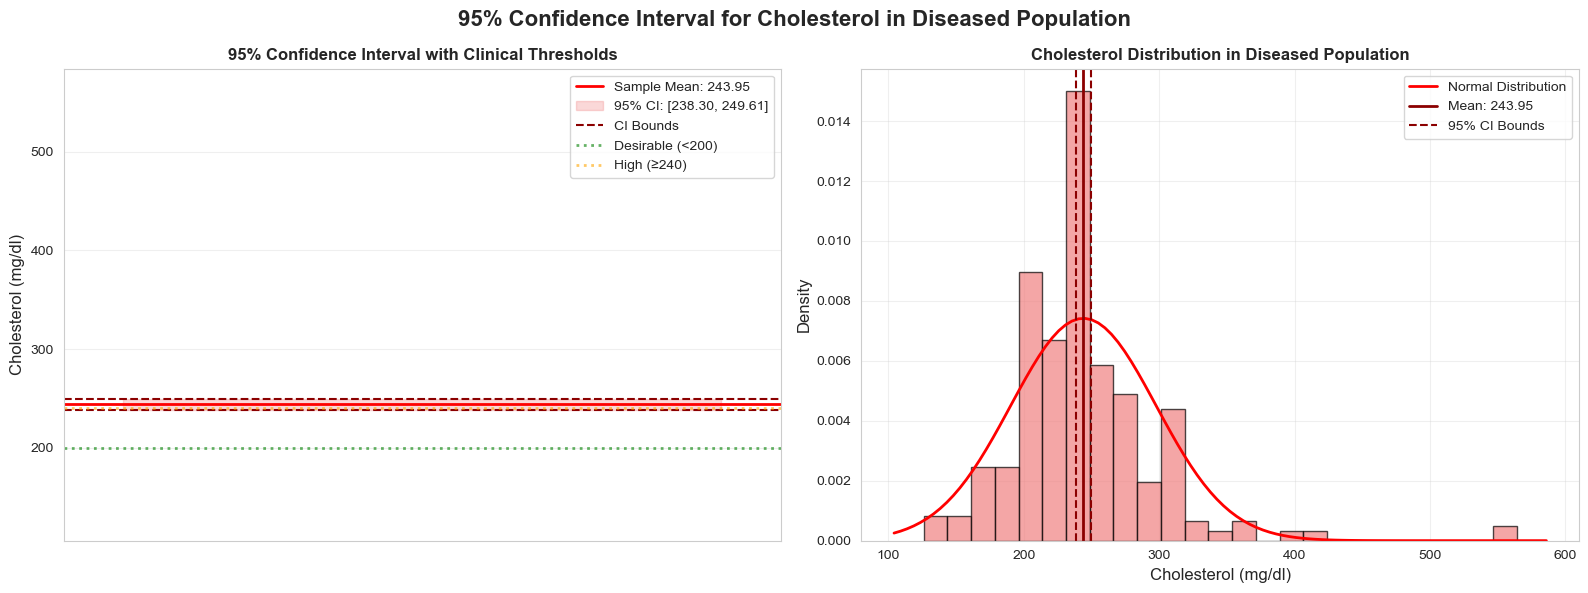


VISUALIZATION EXPLANATION:
--------------------------------------------------

Left plot: Shows the confidence interval as a shaded region
- Red line: Sample mean
- Shaded area: Range where we're 95% confident the true mean lies
- Reference lines: Clinical cholesterol thresholds

Right plot: Shows the actual data distribution
- Histogram: Observed cholesterol values
- Red curve: Theoretical normal distribution
- Vertical lines: Mean and confidence interval bounds



In [64]:
# Visualization of confidence interval

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('95% Confidence Interval for Cholesterol in Diseased Population', fontsize=16, fontweight='bold')

# Plot 1: Confidence interval visualization
ax1 = axes[0]
ax1.axhline(y=mean_diseased, color='red', linewidth=2, label=f'Sample Mean: {mean_diseased:.2f}')
ax1.fill_between([0, 1], ci_lower_diseased, ci_upper_diseased, alpha=0.3, color='lightcoral',
                  label=f'95% CI: [{ci_lower_diseased:.2f}, {ci_upper_diseased:.2f}]')
ax1.axhline(y=ci_lower_diseased, color='darkred', linestyle='--', linewidth=1.5, label='CI Bounds')
ax1.axhline(y=ci_upper_diseased, color='darkred', linestyle='--', linewidth=1.5)

# Add reference lines for clinical thresholds
ax1.axhline(y=200, color='green', linestyle=':', linewidth=2, alpha=0.6, label='Desirable (<200)')
ax1.axhline(y=240, color='orange', linestyle=':', linewidth=2, alpha=0.6, label='High (≥240)')

ax1.set_xlim(-0.1, 1.1)
ax1.set_ylim(diseased_chol.min() - 20, diseased_chol.max() + 20)
ax1.set_ylabel('Cholesterol (mg/dl)', fontsize=12)
ax1.set_title('95% Confidence Interval with Clinical Thresholds', fontsize=12, fontweight='bold')
ax1.legend(loc='best')
ax1.set_xticks([])
ax1.grid(True, alpha=0.3)

# Plot 2: Distribution with CI
ax2 = axes[1]
ax2.hist(diseased_chol, bins=25, color='lightcoral', edgecolor='black', alpha=0.7, density=True)

# Add normal distribution overlay
from scipy.stats import norm as normal_dist
xmin, xmax = ax2.get_xlim()
x = np.linspace(xmin, xmax, 100)
p = normal_dist.pdf(x, mean_diseased, std_diseased)
ax2.plot(x, p, 'r-', linewidth=2, label='Normal Distribution')

# Mark mean and CI
ax2.axvline(mean_diseased, color='darkred', linewidth=2, linestyle='-', label=f'Mean: {mean_diseased:.2f}')
ax2.axvline(ci_lower_diseased, color='darkred', linewidth=1.5, linestyle='--', label='95% CI Bounds')
ax2.axvline(ci_upper_diseased, color='darkred', linewidth=1.5, linestyle='--')

ax2.set_xlabel('Cholesterol (mg/dl)', fontsize=12)
ax2.set_ylabel('Density', fontsize=12)
ax2.set_title('Cholesterol Distribution in Diseased Population', fontsize=12, fontweight='bold')
ax2.legend(loc='best')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nVISUALIZATION EXPLANATION:")
print("-"*50)
print("""
Left plot: Shows the confidence interval as a shaded region
- Red line: Sample mean
- Shaded area: Range where we're 95% confident the true mean lies
- Reference lines: Clinical cholesterol thresholds

Right plot: Shows the actual data distribution
- Histogram: Observed cholesterol values
- Red curve: Theoretical normal distribution
- Vertical lines: Mean and confidence interval bounds
""")

---
# UNIT 3: Advanced Hypothesis Testing and Regression

## Question 1: One-Sample t-test

Perform hypothesis testing to evaluate whether the mean serum cholesterol (chol) of patients with heart disease (target = 1) differs significantly from 245 mg/dl.

In [65]:
# Unit 3, Q1: One-Sample t-test

print("="*100)
print("ONE-SAMPLE T-TEST: CHOLESTEROL vs. REFERENCE VALUE (245 mg/dl)")
print("="*100)

# Test value
mu_0 = 245  # Reference/hypothesized mean

# Use diseased population data
sample_data = diseased_chol
n = len(sample_data)
sample_mean = sample_data.mean()
sample_std = sample_data.std()
sample_se = sample_std / np.sqrt(n)

print("\n1. HYPOTHESES:")
print("="*50)
print(f"H₀ (Null Hypothesis): μ = {mu_0} mg/dl")
print(f"   The mean cholesterol of diseased patients equals {mu_0} mg/dl")
print(f"\nH₁ (Alternative Hypothesis): μ ≠ {mu_0} mg/dl")
print(f"   The mean cholesterol of diseased patients differs from {mu_0} mg/dl")

print("\n2. SIGNIFICANCE LEVEL:")
print("="*50)
print("α = 0.05 (5% significance level)")
print("Test type: Two-tailed")

print("\n3. SAMPLE STATISTICS:")
print("="*50)
print(f"Sample size (n): {n}")
print(f"Sample mean (x̄): {sample_mean:.4f} mg/dl")
print(f"Sample std dev (s): {sample_std:.4f}")
print(f"Standard error (SE): {sample_se:.4f}")
print(f"Hypothesized mean (μ₀): {mu_0} mg/dl")
print(f"Difference (x̄ - μ₀): {sample_mean - mu_0:.4f} mg/dl")

print("\n4. TEST STATISTIC CALCULATION:")
print("="*50)

# Calculate t-statistic
t_statistic_one = (sample_mean - mu_0) / sample_se
df_one = n - 1

print(f"Formula: t = (x̄ - μ₀) / (s/√n)")
print(f"        t = ({sample_mean:.4f} - {mu_0}) / {sample_se:.4f}")
print(f"        t = {t_statistic_one:.6f}")
print(f"\nDegrees of freedom: {df_one}")

# Calculate p-value (two-tailed)
p_value_one = 2 * (1 - t.cdf(abs(t_statistic_one), df_one))

print(f"P-value (two-tailed): {p_value_one:.6f}")

# Critical values
t_critical_lower = t.ppf(0.025, df_one)
t_critical_upper = t.ppf(0.975, df_one)

print(f"\nCritical values (α = 0.05, two-tailed):")
print(f"  t_critical = ±{t_critical_upper:.4f}")
print(f"  Rejection region: t < {t_critical_lower:.4f} or t > {t_critical_upper:.4f}")

print("\n5. DECISION:")
print("="*50)

if p_value_one < 0.05:
    decision = "REJECT"
    conclusion = "There IS sufficient evidence"
else:
    decision = "FAIL TO REJECT"
    conclusion = "There is NOT sufficient evidence"

print(f"Since p-value ({p_value_one:.6f}) {'<' if p_value_one < 0.05 else '>'} α (0.05):")
print(f"Decision: {decision} the null hypothesis")

if abs(t_statistic_one) > t_critical_upper:
    print(f"Since |t| = {abs(t_statistic_one):.4f} > t_critical = {t_critical_upper:.4f}:")
    print(f"The test statistic falls in the rejection region")

print("\n6. INTERPRETATION:")
print("="*50)
print(f"{conclusion} to conclude that the mean serum cholesterol")
print(f"of patients with heart disease differs significantly from {mu_0} mg/dl")
print(f"at the 5% significance level.")

print(f"\nPractical significance:")
print(f"- Sample mean: {sample_mean:.2f} mg/dl")
print(f"- Reference value: {mu_0} mg/dl")
print(f"- Difference: {abs(sample_mean - mu_0):.2f} mg/dl ({'lower' if sample_mean < mu_0 else 'higher'})")

print("\n" + "="*100)

ONE-SAMPLE T-TEST: CHOLESTEROL vs. REFERENCE VALUE (245 mg/dl)

1. HYPOTHESES:
H₀ (Null Hypothesis): μ = 245 mg/dl
   The mean cholesterol of diseased patients equals 245 mg/dl

H₁ (Alternative Hypothesis): μ ≠ 245 mg/dl
   The mean cholesterol of diseased patients differs from 245 mg/dl

2. SIGNIFICANCE LEVEL:
α = 0.05 (5% significance level)
Test type: Two-tailed

3. SAMPLE STATISTICS:
Sample size (n): 350
Sample mean (x̄): 243.9543 mg/dl
Sample std dev (s): 53.7761
Standard error (SE): 2.8745
Hypothesized mean (μ₀): 245 mg/dl
Difference (x̄ - μ₀): -1.0457 mg/dl

4. TEST STATISTIC CALCULATION:
Formula: t = (x̄ - μ₀) / (s/√n)
        t = (243.9543 - 245) / 2.8745
        t = -0.363796

Degrees of freedom: 349
P-value (two-tailed): 0.716231

Critical values (α = 0.05, two-tailed):
  t_critical = ±1.9668
  Rejection region: t < -1.9668 or t > 1.9668

5. DECISION:
Since p-value (0.716231) > α (0.05):
Decision: FAIL TO REJECT the null hypothesis

6. INTERPRETATION:
There is NOT sufficient

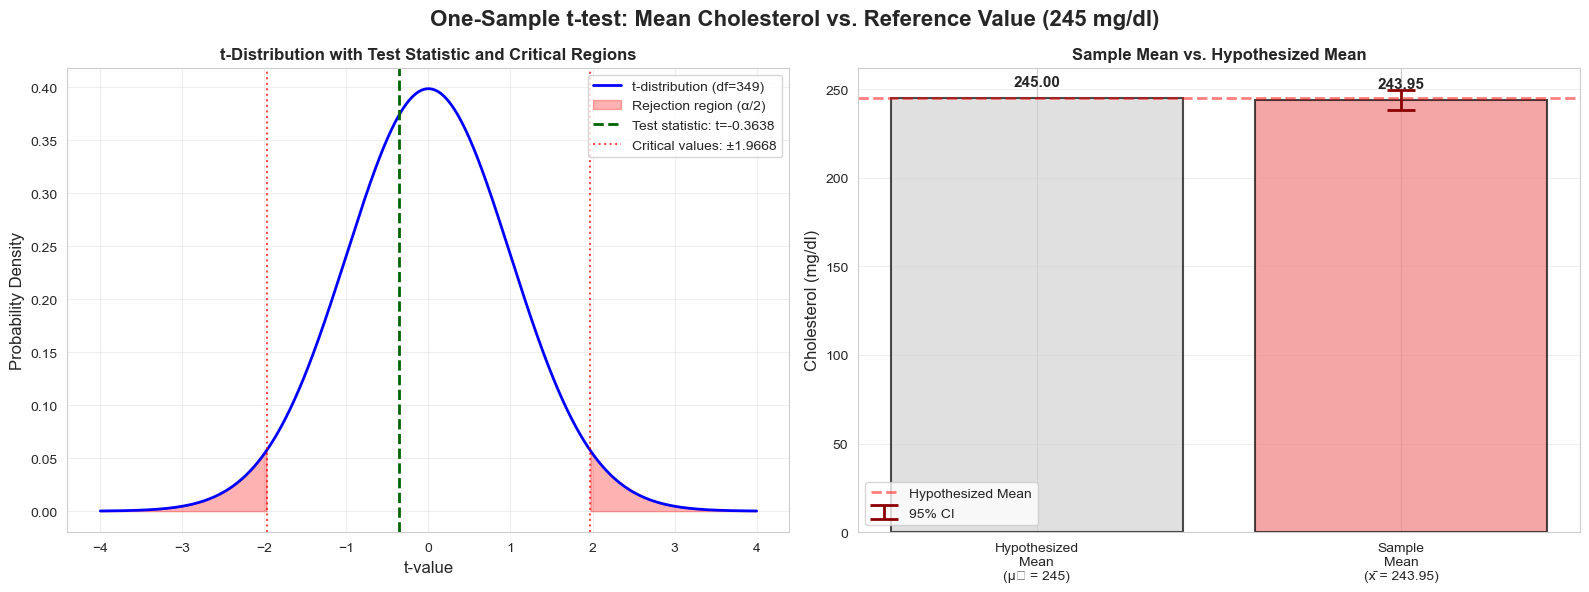


VISUALIZATION INTERPRETATION:
--------------------------------------------------

LEFT PLOT (t-distribution):
- Blue curve: Theoretical t-distribution
- Red shaded areas: Rejection regions (2.5% in each tail)
- Green dashed line: Our calculated test statistic
- If green line falls in red region → reject H₀

RIGHT PLOT (Mean Comparison):
- Gray bar: Hypothesized mean (245 mg/dl)
- Red bar: Observed sample mean
- Error bar: 95% confidence interval for sample mean
- If CI doesn't contain hypothesized mean → reject H₀



In [66]:
# Visualization of one-sample t-test

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(f'One-Sample t-test: Mean Cholesterol vs. Reference Value ({mu_0} mg/dl)', 
             fontsize=16, fontweight='bold')

# Plot 1: t-distribution with test statistic
ax1 = axes[0]
x = np.linspace(-4, 4, 1000)
y = t.pdf(x, df_one)

ax1.plot(x, y, 'b-', linewidth=2, label=f't-distribution (df={df_one})')
ax1.fill_between(x[x <= t_critical_lower], y[x <= t_critical_lower], alpha=0.3, color='red', 
                  label='Rejection region (α/2)')
ax1.fill_between(x[x >= t_critical_upper], y[x >= t_critical_upper], alpha=0.3, color='red')

# Mark test statistic
ax1.axvline(t_statistic_one, color='darkgreen', linewidth=2, linestyle='--', 
            label=f'Test statistic: t={t_statistic_one:.4f}')
ax1.axvline(t_critical_lower, color='red', linewidth=1.5, linestyle=':', alpha=0.7)
ax1.axvline(t_critical_upper, color='red', linewidth=1.5, linestyle=':', alpha=0.7,
            label=f'Critical values: ±{t_critical_upper:.4f}')

ax1.set_xlabel('t-value', fontsize=12)
ax1.set_ylabel('Probability Density', fontsize=12)
ax1.set_title('t-Distribution with Test Statistic and Critical Regions', fontsize=12, fontweight='bold')
ax1.legend(loc='best')
ax1.grid(True, alpha=0.3)

# Plot 2: Sample mean vs hypothesized mean
ax2 = axes[1]

# Create comparison bar chart
values = [mu_0, sample_mean]
labels = [f'Hypothesized\nMean\n(μ₀ = {mu_0})', f'Sample\nMean\n(x̄ = {sample_mean:.2f})']
colors_bar = ['lightgray', 'lightcoral']

bars = ax2.bar(labels, values, color=colors_bar, edgecolor='black', linewidth=1.5, alpha=0.7)

# Add error bar for sample mean
ax2.errorbar(1, sample_mean, yerr=sample_se*t_critical_upper, fmt='none', 
             color='darkred', linewidth=2, capsize=10, capthick=2, label='95% CI')

# Add horizontal line at hypothesized mean
ax2.axhline(mu_0, color='red', linestyle='--', linewidth=2, alpha=0.5, label='Hypothesized Mean')

ax2.set_ylabel('Cholesterol (mg/dl)', fontsize=12)
ax2.set_title('Sample Mean vs. Hypothesized Mean', fontsize=12, fontweight='bold')
ax2.legend(loc='best')
ax2.grid(True, alpha=0.3, axis='y')

# Add value labels
for bar, val in zip(bars, values):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 5,
             f'{val:.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nVISUALIZATION INTERPRETATION:")
print("-"*50)
print("""
LEFT PLOT (t-distribution):
- Blue curve: Theoretical t-distribution
- Red shaded areas: Rejection regions (2.5% in each tail)
- Green dashed line: Our calculated test statistic
- If green line falls in red region → reject H₀

RIGHT PLOT (Mean Comparison):
- Gray bar: Hypothesized mean (245 mg/dl)
- Red bar: Observed sample mean
- Error bar: 95% confidence interval for sample mean
- If CI doesn't contain hypothesized mean → reject H₀
""")

## Question 2: Multiple Linear Regression

Fit a linear regression model to predict Cholesterol using Age, Resting BP, Max Heart Rate, Oldpeak, and CA. Report fit metrics and plot predicted vs actual values.

In [67]:
# Unit 3, Q2: Multiple Linear Regression

print("="*100)
print("MULTIPLE LINEAR REGRESSION: PREDICTING CHOLESTEROL")
print("="*100)

# Define features and target
features = ['age', 'trestbps', 'thalach', 'oldpeak', 'ca']
target = 'chol'

# Prepare data
X = df_cleaned[features].copy()
y = df_cleaned[target].copy()

print("\nMODEL SPECIFICATION:")
print("-"*50)
print(f"Target variable: {target} (Cholesterol)")
print(f"Predictor variables:")
for i, feat in enumerate(features, 1):
    print(f"  {i}. {feat}")

print(f"\nSample size: {len(X)}")

# Check for missing values in features
print(f"\nMissing values check:")
print(X.isnull().sum())

# Fit the model
model = LinearRegression()
model.fit(X, y)

# Get predictions
y_pred = model.predict(X)

# Calculate residuals
residuals = y - y_pred

print("\n" + "="*100)
print("MODEL COEFFICIENTS")
print("="*100)
print(f"\nIntercept (β₀): {model.intercept_:.6f}")
print(f"\nCoefficients (β):")
print("-"*50)

for feat, coef in zip(features, model.coef_):
    print(f"  {feat:15s}: {coef:10.6f}")

print("\n" + "="*100)
print("MODEL FIT METRICS")
print("="*100)

# R-squared
r2 = r2_score(y, y_pred)
# Adjusted R-squared
n = len(y)
p = len(features)
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

# MSE, RMSE, MAE
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y, y_pred)

# Sum of squares
ss_total = np.sum((y - y.mean())**2)
ss_residual = np.sum(residuals**2)
ss_regression = ss_total - ss_residual

print(f"\n1. COEFFICIENT OF DETERMINATION:")
print(f"   R² = {r2:.6f}")
print(f"   Adjusted R² = {adj_r2:.6f}")
print(f"   Interpretation: {r2*100:.2f}% of variance in cholesterol is explained by the model")

print(f"\n2. ERROR METRICS:")
print(f"   MSE (Mean Squared Error) = {mse:.4f}")
print(f"   RMSE (Root Mean Squared Error) = {rmse:.4f} mg/dl")
print(f"   MAE (Mean Absolute Error) = {mae:.4f} mg/dl")

print(f"\n3. SUM OF SQUARES:")
print(f"   SS_Total = {ss_total:.2f}")
print(f"   SS_Regression = {ss_regression:.2f}")
print(f"   SS_Residual = {ss_residual:.2f}")

print(f"\n4. F-STATISTIC:")
f_statistic = (ss_regression / p) / (ss_residual / (n - p - 1))
from scipy.stats import f as f_dist
f_pvalue = 1 - f_dist.cdf(f_statistic, p, n - p - 1)
print(f"   F = {f_statistic:.4f}")
print(f"   p-value = {f_pvalue:.6e}")
if f_pvalue < 0.05:
    print(f"   Result: Model is statistically significant (p < 0.05)")
else:
    print(f"   Result: Model is NOT statistically significant (p > 0.05)")

print("\n" + "="*100)

MULTIPLE LINEAR REGRESSION: PREDICTING CHOLESTEROL

MODEL SPECIFICATION:
--------------------------------------------------
Target variable: chol (Cholesterol)
Predictor variables:
  1. age
  2. trestbps
  3. thalach
  4. oldpeak
  5. ca

Sample size: 642

Missing values check:
age         0
trestbps    0
thalach     0
oldpeak     0
ca          0
dtype: int64

MODEL COEFFICIENTS

Intercept (β₀): 136.209388

Coefficients (β):
--------------------------------------------------
  age            :   1.212735
  trestbps       :   0.118885
  thalach        :   0.183712
  oldpeak        :   1.761360
  ca             :  -0.243446

MODEL FIT METRICS

1. COEFFICIENT OF DETERMINATION:
   R² = 0.047213
   Adjusted R² = 0.039723
   Interpretation: 4.72% of variance in cholesterol is explained by the model

2. ERROR METRICS:
   MSE (Mean Squared Error) = 2453.5747
   RMSE (Root Mean Squared Error) = 49.5336 mg/dl
   MAE (Mean Absolute Error) = 36.1202 mg/dl

3. SUM OF SQUARES:
   SS_Total = 1653250.

In [68]:
# Regression equation and interpretation

print("="*100)
print("REGRESSION EQUATION")
print("="*100)

equation = f"Cholesterol = {model.intercept_:.4f}"
for feat, coef in zip(features, model.coef_):
    sign = "+" if coef >= 0 else "-"
    equation += f" {sign} {abs(coef):.4f}×{feat}"

print(f"\n{equation}")

print("\n" + "="*100)
print("COEFFICIENT INTERPRETATIONS")
print("="*100)

print(f"\nIntercept ({model.intercept_:.4f}):")
print(f"  The predicted cholesterol when all predictors are zero (not meaningful in practice)")

print(f"\nSlope coefficients:")
for feat, coef in zip(features, model.coef_):
    direction = "increases" if coef > 0 else "decreases"
    print(f"\n  {feat}: {coef:.6f}")
    print(f"    For each 1-unit increase in {feat}, cholesterol {direction} by {abs(coef):.4f} mg/dl,")
    print(f"    holding all other variables constant.")

print("\n" + "="*100)
print("MODEL ASSESSMENT")
print("="*100)

if r2 < 0.3:
    fit_quality = "weak"
elif r2 < 0.5:
    fit_quality = "moderate"
elif r2 < 0.7:
    fit_quality = "good"
else:
    fit_quality = "strong"

print(f"""
1. MODEL FIT:
   - R² = {r2:.4f} indicates {fit_quality} fit
   - The model explains {r2*100:.2f}% of cholesterol variation
   - Remaining {(1-r2)*100:.2f}% is due to other factors not in the model

2. PREDICTION ACCURACY:
   - RMSE = {rmse:.2f} mg/dl is the typical prediction error
   - This is {"acceptable" if rmse < 30 else "moderate" if rmse < 50 else "relatively large"} given cholesterol range

3. MODEL SIGNIFICANCE:
   - F-statistic p-value = {f_pvalue:.6e}
   - Model is {"statistically significant" if f_pvalue < 0.05 else "not statistically significant"}

4. PRACTICAL IMPLICATIONS:
   - The model {"can" if r2 > 0.3 else "has limited ability to"} predict cholesterol from these features
   - {"Some" if r2 > 0.1 else "Limited"} relationship exists between predictors and cholesterol
   - Other factors (diet, genetics, medications) likely play important roles
""")

REGRESSION EQUATION

Cholesterol = 136.2094 + 1.2127×age + 0.1189×trestbps + 0.1837×thalach + 1.7614×oldpeak - 0.2434×ca

COEFFICIENT INTERPRETATIONS

Intercept (136.2094):
  The predicted cholesterol when all predictors are zero (not meaningful in practice)

Slope coefficients:

  age: 1.212735
    For each 1-unit increase in age, cholesterol increases by 1.2127 mg/dl,
    holding all other variables constant.

  trestbps: 0.118885
    For each 1-unit increase in trestbps, cholesterol increases by 0.1189 mg/dl,
    holding all other variables constant.

  thalach: 0.183712
    For each 1-unit increase in thalach, cholesterol increases by 0.1837 mg/dl,
    holding all other variables constant.

  oldpeak: 1.761360
    For each 1-unit increase in oldpeak, cholesterol increases by 1.7614 mg/dl,
    holding all other variables constant.

  ca: -0.243446
    For each 1-unit increase in ca, cholesterol decreases by 0.2434 mg/dl,
    holding all other variables constant.

MODEL ASSESSMENT

1

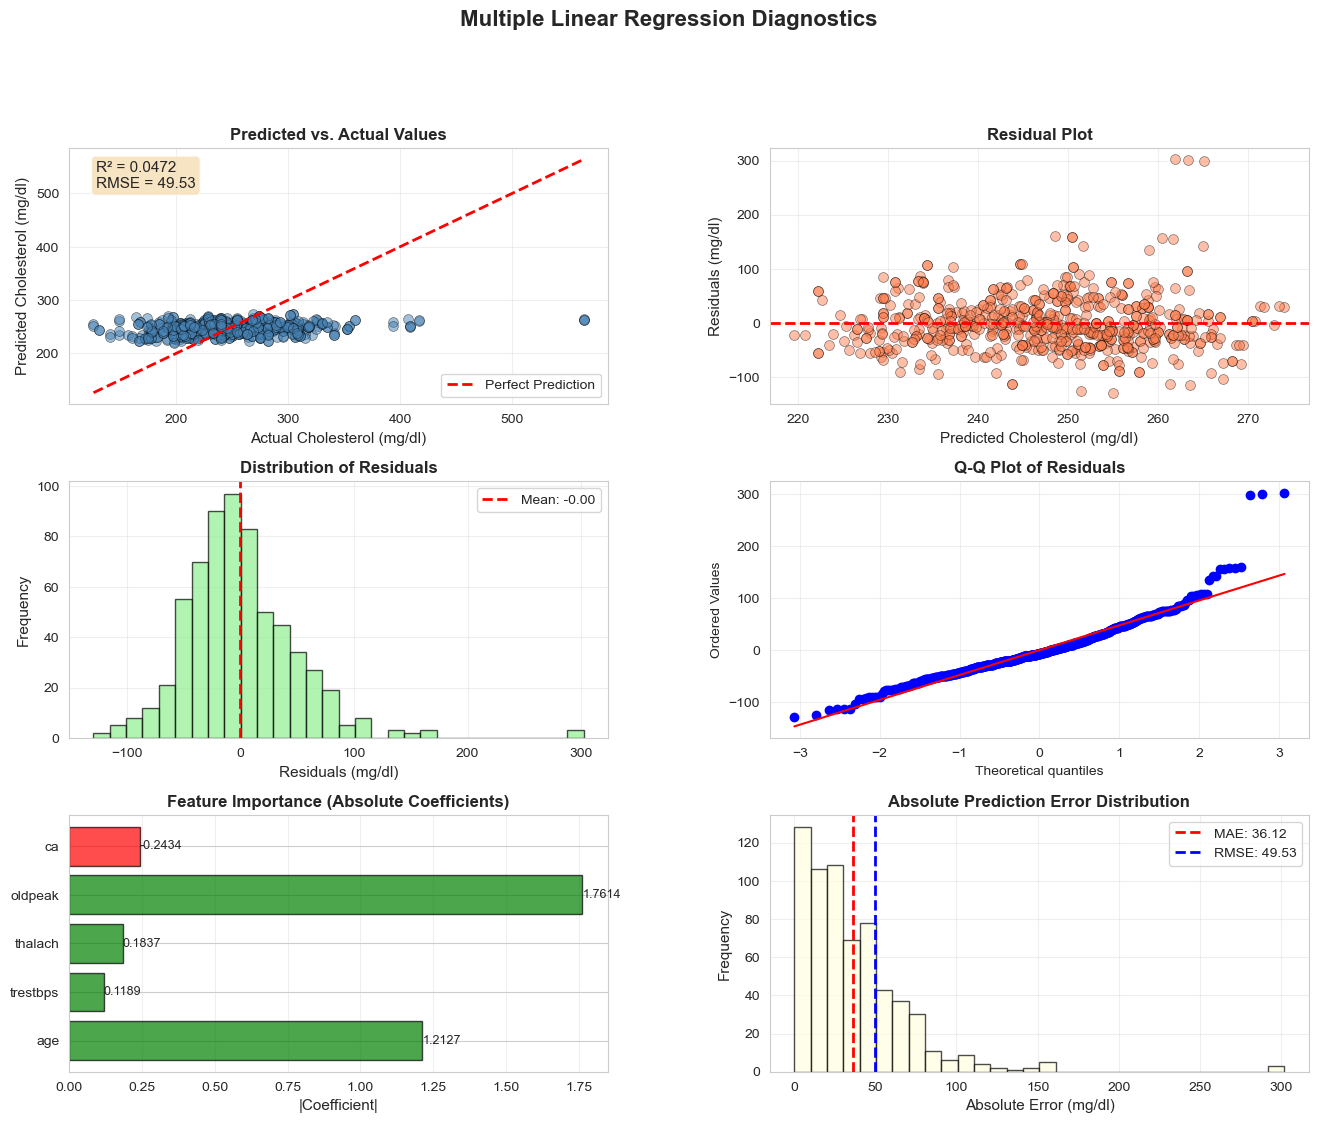

In [69]:
# Visualizations for regression model

fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.3)

# 1. Predicted vs Actual
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(y, y_pred, alpha=0.5, s=50, color='steelblue', edgecolors='black', linewidth=0.5)
ax1.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', linewidth=2, label='Perfect Prediction')

# Add R² text
ax1.text(0.05, 0.95, f'R² = {r2:.4f}\nRMSE = {rmse:.2f}', 
         transform=ax1.transAxes, fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

ax1.set_xlabel('Actual Cholesterol (mg/dl)', fontsize=11)
ax1.set_ylabel('Predicted Cholesterol (mg/dl)', fontsize=11)
ax1.set_title('Predicted vs. Actual Values', fontsize=12, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Residuals vs Predicted
ax2 = fig.add_subplot(gs[0, 1])
ax2.scatter(y_pred, residuals, alpha=0.5, s=50, color='coral', edgecolors='black', linewidth=0.5)
ax2.axhline(y=0, color='r', linestyle='--', linewidth=2)
ax2.set_xlabel('Predicted Cholesterol (mg/dl)', fontsize=11)
ax2.set_ylabel('Residuals (mg/dl)', fontsize=11)
ax2.set_title('Residual Plot', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

# 3. Residuals distribution (histogram)
ax3 = fig.add_subplot(gs[1, 0])
ax3.hist(residuals, bins=30, color='lightgreen', edgecolor='black', alpha=0.7)
ax3.axvline(residuals.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {residuals.mean():.2f}')
ax3.set_xlabel('Residuals (mg/dl)', fontsize=11)
ax3.set_ylabel('Frequency', fontsize=11)
ax3.set_title('Distribution of Residuals', fontsize=12, fontweight='bold')
ax3.legend()
ax3.grid(True, alpha=0.3)

# 4. Q-Q plot for residuals
ax4 = fig.add_subplot(gs[1, 1])
stats.probplot(residuals, dist="norm", plot=ax4)
ax4.set_title('Q-Q Plot of Residuals', fontsize=12, fontweight='bold')
ax4.grid(True, alpha=0.3)

# 5. Feature importance (coefficient magnitude)
ax5 = fig.add_subplot(gs[2, 0])
coef_abs = np.abs(model.coef_)
colors_coef = ['green' if c > 0 else 'red' for c in model.coef_]
bars = ax5.barh(features, coef_abs, color=colors_coef, alpha=0.7, edgecolor='black')
ax5.set_xlabel('|Coefficient|', fontsize=11)
ax5.set_title('Feature Importance (Absolute Coefficients)', fontsize=12, fontweight='bold')
ax5.grid(True, alpha=0.3, axis='x')

# Add value labels
for bar, val, coef in zip(bars, coef_abs, model.coef_):
    ax5.text(val, bar.get_y() + bar.get_height()/2, 
             f'{coef:.4f}', va='center', ha='left', fontsize=9)

# 6. Prediction error distribution
ax6 = fig.add_subplot(gs[2, 1])
abs_errors = np.abs(residuals)
ax6.hist(abs_errors, bins=30, color='lightyellow', edgecolor='black', alpha=0.7)
ax6.axvline(mae, color='red', linestyle='--', linewidth=2, label=f'MAE: {mae:.2f}')
ax6.axvline(rmse, color='blue', linestyle='--', linewidth=2, label=f'RMSE: {rmse:.2f}')
ax6.set_xlabel('Absolute Error (mg/dl)', fontsize=11)
ax6.set_ylabel('Frequency', fontsize=11)
ax6.set_title('Absolute Prediction Error Distribution', fontsize=12, fontweight='bold')
ax6.legend()
ax6.grid(True, alpha=0.3)

plt.suptitle('Multiple Linear Regression Diagnostics', fontsize=16, fontweight='bold', y=0.995)
plt.show()